# 3.3 Tratamento e pré-processamento — método horário de Bak et al. (2025)

Este notebook foi refeito para **agregar os dados de cinco minutos em horas e tratar anomalias, dias incompletos e faltas isoladas**, seguindo a implementação dos autores. Substitui a descrição anterior do protocolo diário por contadores neste notebook. Os experimentos já treinados e as bases originais permanecem preservados.

**Fontes locais:** CSV australiano integral e `Leopoldo_base_consolidada_5min.csv`, gerado por `data.ipynb`. O notebook apenas lê essas fontes; não executa ou altera a consolidação.

**Configuração final: aproveitar todos os blocos elegíveis.** No Brasil, a variável é potência ativa (`total_active_power_w / 1000`), em kW. Na Austrália, as entradas candidatas são potência, GHI, temperatura do ar, umidade relativa e velocidade do vento. Os outros canais elétricos/solares e chuva ficam disponíveis em auditoria horária, sem restringir esse cenário principal.

As lacunas continuam no calendário e cada trecho recebe `bloco_id`. O maior bloco é apenas um diagnóstico, não um limite da base final. O estudo da estação permanece neste notebook como justificativa para manter o Brasil univariado.

**Entradas comuns:** somente potência está disponível e adotada nos dois domínios. As covariáveis australianas podem ser estudadas no domínio de origem; um modelo que as utilize terá contrato diferente do brasileiro. Antes de transferir pesos, deve-se escolher uma arquitetura compatível com essa diferença ou usar o cenário comum AP. Esta preparação não treina nem declara compatível um modelo multivariado com um alvo univariado.

Referências: [Bak et al., DOI](https://doi.org/10.1109/ACCESS.2025.3591040), [1_unify_format.py](https://github.com/gist-ailab/transfer-learning-PV-forecasting/blob/main/data_preprocessing/DKASC_AliceSprings/1_unify_format.py), [2_drop_anomaly.py](https://github.com/gist-ailab/transfer-learning-PV-forecasting/blob/main/data_preprocessing/DKASC_AliceSprings/2_drop_anomaly.py).

Execute de cima para baixo com um kernel que contenha `pandas`, `numpy`, `matplotlib` e `IPython`. As figuras ficam incorporadas e são exportadas em PNG de 300 dpi e PDF vetorial.

**Implementação neste notebook:** todas as etapas, funções auxiliares e figuras estão nas células abaixo. Não há importação de um módulo de pré-processamento nem execução de código do GitHub; os links identificam apenas a referência bibliográfica.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Image, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "Leopoldo_base_consolidada_5min.csv").is_file()
            and (p / "notebooks/tcc/03_03_tratamento_e_preprocessamento.ipynb").is_file())
NOTEBOOK = RAIZ / "notebooks/tcc/03_03_tratamento_e_preprocessamento.ipynb"

def sha256(arquivo):
    h = hashlib.sha256()
    with Path(arquivo).open("rb") as f:
        for bloco in iter(lambda: f.read(1024 * 1024), b""):
            h.update(bloco)
    return h.hexdigest()

pd.set_option("display.max_columns", 18)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

# Entradas físicas: o Brasil mantém AP; a Austrália preserva suas covariáveis.
COLUNAS_COMUNS = ["Active_Power"]
COLUNAS_AU = ["Active_Power", "Global_Horizontal_Radiation",
              "Weather_Temperature_Celsius", "Weather_Relative_Humidity", "Wind_Speed"]
COLUNAS_BR = ["Active_Power"]
COLUNAS_POR_DOMINIO = {"australia": COLUNAS_AU, "brasil": COLUNAS_BR}
# Canais adicionais são exportados para auditoria, sem restringir o cenário principal.
OUTRAS_AU = ["Active_Energy_Delivered_Received", "Current_Phase_Average",
             "Diffuse_Horizontal_Radiation", "Radiation_Global_Tilted",
             "Radiation_Diffuse_Tilted", "Weather_Daily_Rainfall"]
ACUMULADAS_AU = ["Active_Energy_Delivered_Received", "Weather_Daily_Rainfall"]
# Exemplo explícito para contar janelas; não é escolha otimizada para um modelo.
HISTORICO_AUDITORIA = 24
HORIZONTE_AUDITORIA = 1

## 3.3.1 Tratamento da base australiana

A fonte é `data/raw/australia/87-Site_DKA-M9_A+C-Phases.csv`, sem o corte antigo em 2023. A preparação lê os canais numéricos, exceto direção do vento. As cinco entradas candidatas são `Active_Power`, `Global_Horizontal_Radiation`, `Weather_Temperature_Celsius` `Weather_Relative_Humidity` e `Wind_Speed`. Os demais canais são preservados na auditoria.

Os timestamps são ordenados e as observações de cinco minutos agregadas por média horária. A potência permanece em kW; GHI é irradiância média horária na unidade original, usualmente W/m²; temperatura é °C e RH é %. `Wind_Speed` conserva a unidade do CSV original, que precisa ser confirmada antes de comparar magnitudes com outra fonte; não se aplica conversão presumida. Os autores utilizam vento externo em m/s, portanto essa equivalência não é afirmada sem metadados. Energia acumulada e chuva acumulada adicionais conservam a última leitura horária, sem serem convertidas em potência ou energia incremental. Como na uniformização dos autores, o primeiro e o último dia são excluídos para evitar bordas parciais.

**Uma hora completa possui 12 leituras de cinco minutos, mas a média dos autores não exige as 12.** As contagens são exportadas por canal. Assim, continuidade horária após tratamento não comprova cobertura integral da aquisição original.

O cenário principal exige as cinco entradas simultaneamente. Aplica-se a triagem elétrica e meteorológica dos autores e preservam-se **todos os blocos** completos depois de descartar dias e interpolar faltas isoladas. Os canais auxiliares não tornam esse conjunto mais restritivo; sua disponibilidade fica auditada separadamente.

In [2]:
def agregar_horas(frame, acumuladas=()):
    """Média dos valores presentes, como os autores; contagem auditada separadamente.

    Campos acumulados adicionados pelo pesquisador conservam a última leitura:
    não são potência e não constavam do conjunto de entradas dos autores.
    """
    if not frame.index.is_unique: raise ValueError('Fonte de cinco minutos com duplicatas.')
    numericos = frame.apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
    media = numericos.resample('h').mean()
    contagem = numericos.resample('h').count()
    for c in acumuladas:
        if c in numericos: media[c] = numericos[c].resample('h').last()
    return media, contagem

In [3]:
raiz = RAIZ.resolve()
pasta = raiz/'reports/tcc/preprocessamento_horario_bak2025'
tabdir, figdir = pasta/'tabelas', pasta/'figuras'
tabdir.mkdir(parents=True, exist_ok=True); figdir.mkdir(exist_ok=True)
pa = raiz/'data/raw/australia/87-Site_DKA-M9_A+C-Phases.csv'
pb = raiz/'Leopoldo_base_consolidada_5min.csv'
origens = [pa, pb, raiz/'data.ipynb']
hashes = {str(p.relative_to(raiz)): sha256(p) for p in origens}
print('Lendo dados de cinco minutos; processamento novo em horas.', flush=True)
au = pd.read_csv(pa, usecols=['timestamp']+COLUNAS_AU+OUTRAS_AU)
ts = pd.to_datetime(au.pop('timestamp'), errors='raise', format='mixed')
au.index = pd.DatetimeIndex(ts, name='timestamp'); au = au.sort_index()
# Mesmo recorte das bordas implementado em 1_unify_format.py.
ini = au.index.min().normalize()+pd.Timedelta(days=1)
fim = au.index.max().normalize()
au = au.loc[(au.index>=ini)&(au.index<fim)]
horario_au, count_au = agregar_horas(au, ACUMULADAS_AU)

display(horario_au.head())
display(count_au[COLUNAS_AU].describe().T)

Lendo dados de cinco minutos; processamento novo em horas.


,Active_Energy_Delivered_Received,Current_Phase_Average,Active_Power,Wind_Speed,Weather_Temperature_Celsius,Weather_Relative_Humidity,Global_Horizontal_Radiation,Diffuse_Horizontal_Radiation,Weather_Daily_Rainfall,Radiation_Global_Tilted,Radiation_Diffuse_Tilted
timestamp,,,,,,,,,,,
2013-07-26 00:00:00,229538.0000,1.0000,0.0000,0.6419,2.8018,74.6568,3.3087,1.5230,0.0000,3.6901,1.7560
2013-07-26 01:00:00,229538.0000,1.0000,0.0000,0.8580,1.9832,79.5139,2.9006,1.1270,0.0000,3.2917,1.4106
2013-07-26 02:00:00,229538.0000,1.0000,0.0000,1.1741,1.5173,82.1987,3.1206,1.3068,0.0000,3.3399,1.4178
2013-07-26 03:00:00,229538.0000,1.0000,0.0000,0.7414,0.8974,84.4369,2.9282,1.1074,0.0000,3.3166,1.4346
2013-07-26 04:00:00,229538.0000,1.0000,0.0000,0.7850,0.5053,85.8823,3.0353,1.1796,0.0000,3.1707,1.3174


,count,mean,std,min,25%,50%,75%,max
Active_Power,105864.0000,11.6134,1.5220,0.0000,12.0000,12.0000,12.0000,12.0000
Global_Horizontal_Radiation,105864.0000,11.5615,1.7185,0.0000,12.0000,12.0000,12.0000,12.0000
Weather_Temperature_Celsius,105864.0000,11.5610,1.7192,0.0000,12.0000,12.0000,12.0000,12.0000
Weather_Relative_Humidity,105864.0000,11.5611,1.7191,0.0000,12.0000,12.0000,12.0000,12.0000
Wind_Speed,105864.0000,3.2195,5.3166,0.0000,0.0000,0.0000,12.0000,12.0000


### Artigo, implementação dos autores e escolhas desta reprodução

A tabela documenta as diferenças entre o artigo e o código de referência. Na Austrália, aplicam-se as regras elétricas e meteorológicas disponíveis; no Brasil, somente as regras elétricas.

| Item | Algoritmo apresentado no artigo | Código consultado |
|---|---|---|
| Temperatura mínima | −30 °C | −10 °C |
| Potência baixa com GHI > 200 | Potência normalizada igual a zero | Potência normalizada até 0,05 |
| Referência da normalização para QC | Conferir definição na implementação | Máximo horário observado no período de referência |
| Potência pequena negativa | Não explicitada no trecho | AP/máximo em [−0,05,0) vira zero; abaixo disso vira NaN |
| Potência constante | Resumo como dez valores iguais | Dez comparações consecutivas; sinaliza a 11ª observação em diante, preservando zero |

**Aplicação:** nos dois países, AP/máximo em [−0,05,0) vira zero, abaixo de −0,05 vira NaN, e a repetição não nula segue as dez comparações da implementação. Na Austrália, GHI > 2000, temperatura < −10 °C e RH fora de 0–100% invalidam seus canais; AP ≤ 0,05 com GHI > 200 e AP > 0,1 com GHI < 10 invalidam potência. Velocidade do vento negativa é invalidada na Austrália. A chamada australiana usa `usar_meteorologia=True`; a brasileira usa `False`.

O Brasil mantém QC elétrico, sem fabricar meteorologia nem aplicar limiares a um GHI cuja escala é incerta. Esse controle não identifica todas as falhas que dependeriam da irradiância. Essa diferença de triagem entre domínios fica documentada e a disponibilidade não comprova qualidade física do alvo.

A normalização pelo máximo do período é reproduzida para a **triagem retrospectiva** dos autores. Ela utiliza informação do período inteiro e não deve ser confundida com um padronizador de modelo ajustado exclusivamente no treino. Um experimento prospectivo rigoroso precisará fixar a referência de QC em informação disponível antes da avaliação.

**Salvaguardas explicitadas:** mantemos a grade horária completa; não comprimimos dias removidos; só interpolamos uma falta inteira de uma hora, com as duas bordas válidas; não extrapolamos as bordas. O script dos autores define uma função para recompor horários que não chama no laço principal e interpola depois de retirar dias. Aqui preservamos as datas para impedir ligações artificiais através de interrupções.

In [4]:
def repeticao_autores(power, min_comparacoes=10):
    """Replica o código: dez comparações iguais, marca a 11ª observação em diante.

    A condição é não nula. O texto do artigo resume isso como dez valores iguais.
    """
    iguais = power.ne(0) & power.eq(power.shift(1))
    contagem = iguais.groupby(iguais.ne(iguais.shift()).cumsum()).cumsum()
    return contagem.ge(min_comparacoes)


def limpar_anomalias(horario, usar_meteorologia=True):
    """Limiares do 2_drop_anomaly.py consultado; regras ausentes são documentadas."""
    x = horario.copy().astype(float)
    flags = pd.DataFrame(index=x.index)
    eventos = []
    def invalidar(regra, coluna, mascara):
        mascara = mascara.fillna(False).astype(bool)
        flags[regra] = mascara
        n = int((mascara & x[coluna].notna()).sum())
        x.loc[mascara, coluna] = np.nan
        eventos.append(dict(regra=regra, coluna=coluna, horas_sinalizadas=int(mascara.sum()), novos_nan=n))
    pmax = x.Active_Power.max()
    if not np.isfinite(pmax) or pmax <= 0: raise ValueError('Máximo de potência não positivo.')
    normalizada = x.Active_Power/pmax
    pequenas = normalizada.ge(-.05) & normalizada.lt(0)
    x.loc[pequenas, 'Active_Power'] = 0.
    eventos.append(dict(regra='potencia_negativa_entre_menos005_e_zero_convertida_zero', coluna='Active_Power', horas_sinalizadas=int(pequenas.sum()), novos_nan=0))
    invalidar('potencia_normalizada_menor_menos005', 'Active_Power', normalizada.lt(-.05))
    pmax = float(x.Active_Power.max())
    normalizada = x.Active_Power/pmax
    if usar_meteorologia:
        for c, nome, condicao in [
            ('Global_Horizontal_Radiation', 'ghi_maior_2000', lambda s: s.gt(2000)),
            ('Weather_Temperature_Celsius', 'temperatura_menor_menos10', lambda s: s.lt(-10)),
            ('Wind_Speed', 'vento_negativo', lambda s: s.lt(0)),
            ('Weather_Relative_Humidity', 'umidade_fora_0_100', lambda s: ~s.between(0, 100)&s.notna())]:
            if c in x: invalidar(nome, c, condicao(x[c]))
        if 'Global_Horizontal_Radiation' in x:
            invalidar('potencia_normalizada_ate005_ghi_acima200', 'Active_Power', normalizada.le(.05)&x.Global_Horizontal_Radiation.gt(200))
            invalidar('potencia_normalizada_acima01_ghi_abaixo10', 'Active_Power', normalizada.gt(.1)&x.Global_Horizontal_Radiation.lt(10))
    invalidar('potencia_nao_nula_repetida_10_comparacoes', 'Active_Power', repeticao_autores(x.Active_Power))
    return x, flags, pd.DataFrame(eventos), pmax

In [5]:
limpo_au, flags_au, regras_au, max_au = limpar_anomalias(horario_au, usar_meteorologia=True)

display(regras_au)

,regra,coluna,horas_sinalizadas,novos_nan
0,potencia_negativa_entre_menos005_e_zero_convertida_zero,Active_Power,3072,0
1,potencia_normalizada_menor_menos005,Active_Power,0,0
2,ghi_maior_2000,Global_Horizontal_Radiation,0,0
3,temperatura_menor_menos10,Weather_Temperature_Celsius,255,255
4,vento_negativo,Wind_Speed,6,6
5,umidade_fora_0_100,Weather_Relative_Humidity,1184,1184
6,potencia_normalizada_ate005_ghi_acima200,Active_Power,10,10
7,potencia_normalizada_acima01_ghi_abaixo10,Active_Power,152,152
8,potencia_nao_nula_repetida_10_comparacoes,Active_Power,0,0


## 3.3.2 Tratamento da base brasileira

A única fonte brasileira de entrada é **`Leopoldo_base_consolidada_5min.csv`**. Sua grade preserva registros elétricos mesmo quando a estação não possui medições. `data.ipynb` seleciona o código `07-07FX`, associa as fontes independentemente e soma as parcelas disponíveis com `min_count=1`.

A variável escolhida é **potência total informada**, `total_active_power_w`, convertida de W para kW pela divisão por 1000. Não se usa `daily_power_yields_kwh` para selecionar o período e não se reconstrói energia diária pelos contadores.

O calendário local `America/Sao_Paulo` é obtido da coluna `datetime` em UTC. A faixa começa no dia do primeiro registro válido de potência e termina no dia do último, sem usar o início da estação como limitador. Calculam-se médias horárias, aplicam-se as regras elétricas disponíveis e reprovam-se dias com duas horas NaN consecutivas de potência. Uma hora isolada pode ser interpolada.

**Adaptação necessária:** o Brasil fica univariado, como solicitado. Não se fabricam umidade ou vento, nem se aplicam testes cruzados com um GHI cuja escala local ainda precisa de confirmação. Portanto, não se afirma reprodução multivariada idêntica do artigo no Brasil.

**Soma parcial:** `n_inversores_potencia` identifica o número de contribuintes nos cinco minutos. Uma soma numérica com menos de oito inversores não comprova potência integral da usina. Exportamos, por hora, o número de leituras elétricas, o número com oito contribuintes e o número com contribuição parcial.

In [6]:
br = pd.read_csv(pb, low_memory=False)
br = br.loc[br.usine_code.eq('07-07FX')].copy()
ts = pd.to_datetime(br.pop('datetime'), utc=True, errors='raise', format='mixed').dt.tz_convert('America/Sao_Paulo').dt.tz_localize(None)
br.index = pd.DatetimeIndex(ts, name='timestamp'); br = br.sort_index()
if not br.index.is_unique: raise ValueError('Duplicatas no consolidado brasileiro.')
power = pd.to_numeric(br.total_active_power_w, errors='coerce')/1000
primeiro, ultimo = power.first_valid_index(), power.last_valid_index()
if primeiro is None: raise ValueError('Não há potência brasileira.')
# Preserva dias com observação elétrica; não usa os limites de datas da estação.
faixa = br.loc[primeiro.normalize():ultimo.normalize()+pd.Timedelta(hours=23, minutes=55)]
horario_br, count_br = agregar_horas(pd.DataFrame({'Active_Power': power.reindex(faixa.index)}))
limpo_br, flags_br, regras_br, max_br = limpar_anomalias(horario_br, usar_meteorologia=False)
n = pd.to_numeric(br.n_inversores_potencia, errors='coerce')
n8 = (power.notna()&n.eq(8)).resample('h').sum().reindex(horario_br.index, fill_value=0)
parcial = (power.notna()&n.lt(8)).resample('h').sum().reindex(horario_br.index, fill_value=0)
count_br['n_leituras_oito_inversores'] = n8
count_br['n_leituras_soma_parcial'] = parcial

display(horario_br.head())
display(regras_br)

,Active_Power
timestamp,
2025-01-02 00:00:00,NaN
2025-01-02 01:00:00,NaN
2025-01-02 02:00:00,NaN
2025-01-02 03:00:00,NaN
2025-01-02 04:00:00,NaN


,regra,coluna,horas_sinalizadas,novos_nan
0,potencia_negativa_entre_menos005_e_zero_convertida_zero,Active_Power,0,0
1,potencia_normalizada_menor_menos005,Active_Power,0,0
2,potencia_nao_nula_repetida_10_comparacoes,Active_Power,0,0


## 3.3.3 Construção das bases horárias e médias diárias derivadas

Para potência e variáveis instantâneas, utiliza-se a média das observações disponíveis dentro de cada hora:

$$\bar x_h = \frac{1}{n_h}\sum_{k\in\mathcal O_h}x_k.$$

Uma hora com 8 leituras terá a média dessas 8, e não uma soma nem uma estimativa automática das 4 ausentes. A potência permanece em kW, sem usar contadores de energia como potência.

O produto principal agora é **horário**. Uma base diária auxiliar também é exportada, para todos os dias civis completos com 24 valores horários em um mesmo bloco. Ela usa a média das 24 potências horárias e contabiliza quantas leituras de cinco minutos deram origem a essas horas. Uma média de 24 horas com cobertura parcial não garante 288 leituras originais e pode diferir da média direta das amostras de cinco minutos.

Essa construção substitui, nesta nova preparação, o alvo antigo por contadores/24. As bases e métricas antigas continuam preservadas em seus diretórios, mas não descrevem os novos dados.

## 3.3.4 Tratamento dos valores ausentes e seleção dos intervalos

Depois do QC, qualquer coluna **exigida** com duas horas NaN consecutivas reprova o dia. Lacunas inteiras de uma hora podem ser preenchidas linearmente; lacunas maiores e dias removidos não recebem preenchimento parcial. Duas horas observadas que cercam uma falta isolada têm dois horários de diferença.

As máscaras `interpolado_*` identificam cada valor estimado. `potencia_observada_horaria` exige potência sem interpolação e sem mudança em relação à média horária original. `disponivel_em` registra quando a última borda usada no histórico se torna conhecida. Uma previsão emitida antes dessa data não pode utilizar a estimativa interpolada; alvos alterados/interpolados não devem ser tratados como medições de teste.

**Seleção final:** preservam-se **todos os blocos elegíveis**, sem limitar a exportação ao maior. O Brasil exige somente AP; a Austrália exige as cinco entradas candidatas. `bloco_id` identifica cada sequência horária contínua. O CSV compacto conserva as datas originais e o identificador; ele não deve ser interpretado como uma única sequência regular. O CSV de calendário conserva inclusive as horas descartadas, com `bloco_id=0`.

**Janelas e partições:** qualquer janela de histórico mais alvo deve permanecer no mesmo bloco. A auditoria exemplifica 24 horas de histórico e alvo uma hora à frente, sem atravessar blocos nem as partições cronológicas. São parâmetros demonstrativos, não hiperparâmetros escolhidos por validação. A média com rótulo hh:00 só está disponível ao terminar essa hora; uma falta interpolada só está disponível ao fim da hora da sua borda direita. A contagem de teste distingue alvos observados de estimados.

O maior período horário pode ser muito maior que o maior período de cinco minutos porque a média horária permanece disponível quando faltam apenas algumas amostras intrahorárias. As contagens exportadas mantêm essa diferença visível.

Na resolução horária, duas observações consecutivas ausentes representam duas horas de cobertura ausente. Essa regra não é aplicada às linhas originais de cinco minutos.

A detecção segue a sequência cronológica das horas e pode alcançar a meia-noite, como no código dos autores. Dias removidos permanecem no calendário com valores ausentes. Eventuais bordas ou faltas residuais que não podem ser interpoladas continuam incompletas e interrompem os blocos.

In [7]:
def validar_horas(index):
    if not isinstance(index, pd.DatetimeIndex) or index.empty or not index.is_unique:
        raise ValueError('Esperada uma grade horária única e não vazia.')
    if not index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all():
        raise ValueError('Recomponha o calendário horário antes de procurar lacunas/blocos.')


def blocos_consecutivos(mascara):
    validar_horas(mascara.index)
    if mascara.isna().any(): raise ValueError('Máscara incompleta.')
    x = np.r_[False, mascara.to_numpy(dtype=bool), False].astype(int)
    a, b = np.flatnonzero(np.diff(x)==1), np.flatnonzero(np.diff(x)==-1)-1
    return pd.DataFrame({'inicio': mascara.index[a], 'fim': mascara.index[b],
                         'horas': b-a+1, 'dias_equivalentes': (b-a+1)/24})


def maior_bloco(mascara):
    g = blocos_consecutivos(mascara)
    if g.empty: raise ValueError('Não existe bloco completo com as colunas exigidas.')
    return g.loc[g.horas.idxmax()]


def remover_dias_e_interpolar(horario, obrigatorias, acumuladas=()):
    """Duas horas NaN consecutivas em qualquer coluna exigida reprovam o dia.

    Mantém o calendário; interpola somente lacunas INTEIRAS de uma hora,
    internas, com as duas bordas observadas. Não comprime dias descartados.
    """
    validar_horas(horario.index)
    x = horario.copy()
    nulos = x[obrigatorias].isna()
    dois = nulos.rolling(2, min_periods=2).sum().ge(2)
    datas = x.index.normalize()
    dias_ruins = pd.DatetimeIndex(datas[dois.any(axis=1)]).unique()
    rejeitado = pd.Series(datas.isin(dias_ruins), index=x.index)
    x.loc[rejeitado, obrigatorias] = np.nan
    imputados = pd.DataFrame(False, index=x.index, columns=obrigatorias)
    disponibilidade = pd.DataFrame(index=x.index)
    for c in obrigatorias:
        s = x[c]
        na = s.isna()
        grupos = na.ne(na.shift(fill_value=False)).cumsum()
        tamanho = na.groupby(grupos).transform('sum')
        ok = na & tamanho.eq(1) & s.ffill().notna() & s.bfill().notna() & ~rejeitado
        if c in acumuladas: ok &= s.bfill().ge(s.ffill())
        valor = s.interpolate(method='time', limit_area='inside')
        x.loc[ok, c] = valor[ok]
        imputados[c] = ok
        tempos = pd.Series(s.index, index=s.index).where(s.notna())
        disponibilidade[c] = tempos.where(~ok, tempos.bfill())
    completo = x[obrigatorias].notna().all(axis=1)
    diaria = pd.DataFrame({'duas_nan_em_alguma_coluna': dois.any(axis=1),
                          'dia_reprovado_duas_nan': rejeitado,
                          'hora_completa_apos': completo,
                          'valores_interpolados': imputados.sum(axis=1)}, index=x.index).resample('D').agg(
        duas_nan_em_alguma_coluna=('duas_nan_em_alguma_coluna', 'any'),
        dia_reprovado_duas_nan=('dia_reprovado_duas_nan', 'any'),
        horas_completas=('hora_completa_apos', 'sum'), valores_interpolados=('valores_interpolados', 'sum'))
    diaria['dia_24h_completo'] = diaria.horas_completas.eq(24)
    return x, imputados, disponibilidade, diaria

def identificar_blocos(mascara):
    """Identificador por sequência horária contínua; zero nas horas não elegíveis."""
    validar_horas(mascara.index)
    if mascara.isna().any():
        raise ValueError("Máscara incompleta.")
    inicio = mascara & ~mascara.shift(fill_value=False)
    return inicio.cumsum().where(mascara, 0).astype("int64").rename("bloco_id")


def auditar_janelas_blocos(dados, colunas, historico=24, horizonte=1):
    """Lista janelas sem atravessar blocos/partições nem usar preenchimento futuro."""
    if historico < 1 or horizonte < 1:
        raise ValueError("Histórico e horizonte precisam ser positivos.")
    itens = []
    for (bloco, particao), grupo in dados.groupby(["bloco_id", "particao_proposta"], sort=False):
        grupo = grupo.sort_index()
        if bloco <= 0 or len(grupo) < historico+horizonte:
            continue
        validar_horas(grupo.index)
        fins = np.arange(historico-1, len(grupo)-horizonte)
        alvos = fins+horizonte
        completos = grupo[colunas].notna().all(axis=1).rolling(historico).sum().eq(historico).to_numpy()[fins]
        disponivel = pd.to_datetime(grupo.disponivel_em).to_numpy(dtype="datetime64[ns]")
        ultima_borda = np.lib.stride_tricks.sliding_window_view(disponivel, historico).max(axis=1)[:len(fins)]
        emissao = grupo.index[fins]+pd.Timedelta(hours=1)
        elegivel = completos & grupo.Active_Power.notna().to_numpy()[alvos]
        elegivel &= ~np.isnat(ultima_borda) & (ultima_borda <= emissao.to_numpy())
        fins, alvos, emissao = fins[elegivel], alvos[elegivel], emissao[elegivel]
        itens.append(pd.DataFrame(dict(
            bloco_id=int(bloco), particao=particao,
            inicio_historico=grupo.index[fins-historico+1], fim_historico=grupo.index[fins],
            alvo=grupo.index[alvos], emissao=emissao,
            alvo_observado=grupo.potencia_observada_horaria.to_numpy()[alvos])))
    campos = ["bloco_id", "particao", "inicio_historico", "fim_historico", "alvo", "emissao", "alvo_observado"]
    return pd.concat(itens, ignore_index=True)[campos] if itens else pd.DataFrame(columns=campos)

In [8]:
tratado_au, imp_au, disp_au, dias_au = remover_dias_e_interpolar(
    limpo_au, COLUNAS_AU)
tratado_br, imp_br, disp_br, dias_br = remover_dias_e_interpolar(
    limpo_br, COLUNAS_BR)
for dominio, diaria in [("Austrália", dias_au), ("Brasil", dias_br)]:
    print(dominio, "— calendário, reprovados e completos:", len(diaria),
          int(diaria.dia_reprovado_duas_nan.sum()), int(diaria.dia_24h_completo.sum()))

Austrália — calendário, reprovados e completos: 4411 3298 1111
Brasil — calendário, reprovados e completos: 364 101 261


## 3.3.5 Normalização e padronização

Há três escalas diferentes, mantidas separadas:

1. **Triagem dos autores:** AP dividida pelo máximo horário do período, usada para os limiares de QC. É retrospectiva e não é ajustada só no treino.
2. **Escala física:** potência em kW dividida pelas capacidades AC adotadas de 24 kW e 1000 kW. Esses parâmetros requerem confirmação técnica definitiva. Essa divisão não remove diferenças de tecnologia, disponibilidade ou contribuição parcial.
3. **Z-score preparatório da potência:** média e desvio populacional ajustados somente nos primeiros 70% das horas elegíveis de todos os blocos de cada domínio, excluindo estimativas cuja borda de potência só chega depois do fim do treino. Validação e teste usam os mesmos parâmetros.

As partições 70%/15%/15% são **uma proposta de preparação**, não uma validação concluída. Não reutilizam as antigas 160/26/44 janelas. Nenhum modelo foi treinado ou comparado nesta execução.

**Contrato de entradas:** Brasil: AP; Austrália: AP, GHI, temperatura, RH e vento. A entrada física comum é AP. Os z-scores das cinco variáveis australianas também são exportados, com estatísticas ajustadas somente no treino proposto. Normalizar não cria no Brasil as covariáveis ausentes nem torna automaticamente compatíveis modelos com dimensões de entrada diferentes.

As partições são definidas por data sobre todas as horas elegíveis, sem divisão aleatória e sem reiniciar 70/15/15 em cada bloco. A auditoria de janelas aplica as fronteiras de bloco e de partição. `potencia_pu_capacidade`, `potencia_z_treino` e `Active_Power_z_treino` são representações alternativas de AP, não três medições independentes. Máscaras, contagens, bloco e partição são metadados, não entradas adicionais.

A próxima célula identifica e exporta todos os blocos, conserva as máscaras de interpolação, prepara as partições e calcula as escalas. Não treina modelos.

In [9]:
criterios, resumo_blocos, escalas_variaveis = [], [], []
conjuntos = [('australia', COLUNAS_AU, horario_au, limpo_au, tratado_au, imp_au, disp_au, count_au, dias_au, 24.),
             ('brasil', COLUNAS_BR, horario_br, limpo_br, tratado_br, imp_br, disp_br, count_br, dias_br, 1000.)]
frames, frames_maiores, blocos, diarios = {}, {}, {}, {}
faltantes, qualidade_diaria, particoes, escalas, exportados, janelas = [], [], [], [], {}, {}

def exportar(nome, frame, relativo):
    path = raiz/relativo
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index_label='timestamp', compression={'method':'gzip', 'mtime':0})
    exportados[nome] = dict(arquivo=relativo, linhas=len(frame), sha256=sha256(path))

for dom, cols, bruto, qc, final, imp, disp, count, diaria, cap in conjuntos:
    mascara = final[cols].notna().all(axis=1)
    ids = identificar_blocos(mascara)
    lista = blocos_consecutivos(mascara)
    lista.insert(0, 'bloco_id', np.arange(1, len(lista)+1))
    blocos[dom] = lista
    b = maior_bloco(mascara)
    criterios.append(dict(dominio=dom, papel='Maior bloco: diagnóstico', **b.to_dict(), colunas_exigidas='; '.join(cols)))
    # Todas as horas completas; datas são preservadas mesmo no CSV compacto.
    s = final.loc[mascara, cols].copy()
    s['bloco_id'] = ids.loc[s.index]
    for c in cols:
        s['interpolado_'+c] = imp.loc[s.index, c]
        s['n_5min_'+c] = count.loc[s.index, c]
        faltantes.append(dict(dominio=dom, variavel=c, horas_calendario=len(bruto),
                              ausentes_apos_media=int(bruto[c].isna().sum()),
                              novos_nan_qc=int((bruto[c].notna()&qc[c].isna()).sum()),
                              interpolados_total=int(imp[c].sum()),
                              interpolados_base_final=int(imp.loc[s.index,c].sum()),
                              ausentes_apos_dias_e_interpolacao=int(final[c].isna().sum())))
    s['potencia_nao_interpolada'] = ~imp.loc[s.index, 'Active_Power']
    s['potencia_observada_horaria'] = s.potencia_nao_interpolada & s.Active_Power.eq(bruto.loc[s.index, 'Active_Power'])
    # Rótulos hh:00 resumem [hh:00, hh+1:00): a leitura só está pronta ao fim da hora.
    s['disponivel_em'] = disp.loc[s.index, cols].max(axis=1)+pd.Timedelta(hours=1)
    s['potencia_pu_capacidade'] = s.Active_Power/cap
    # Ordenação por data, em todos os blocos; nenhuma divisão aleatória.
    a, v = int(len(s)*.7), int(len(s)*.85)
    if not 0<a<v<len(s): raise ValueError('Base muito curta para propor três partições.')
    s['particao_proposta'] = np.select([np.arange(len(s))<a, np.arange(len(s))<v], ['treino','validacao'], default='teste')
    fim_treino_disponivel = s.index[a-1]+pd.Timedelta(hours=1)
    usar = s.particao_proposta.eq('treino') & s.disponivel_em.le(fim_treino_disponivel)
    media = float(s.loc[usar,'potencia_pu_capacidade'].mean())
    std = float(s.loc[usar,'potencia_pu_capacidade'].std(ddof=0))
    std = std if std>1e-8 else 1.
    s['potencia_z_treino'] = (s.potencia_pu_capacidade-media)/std
    escalas.append(dict(dominio=dom, capacidade_ac_kw=cap, media_treino_pu=media, desvio_treino_pu=std,
                        n_ajuste=int(usar.sum()), maximo_horario_referencia_qc=max_au if dom=='australia' else max_br))
    for c in cols:
        media_c, std_c = float(s.loc[usar,c].mean()), float(s.loc[usar,c].std(ddof=0))
        std_c = std_c if std_c>1e-8 else 1.
        s[c+'_z_treino'] = (s[c]-media_c)/std_c
        escalas_variaveis.append(dict(dominio=dom, variavel=c, media_treino=media_c,
                                      desvio_treino=std_c, n_ajuste=int(usar.sum())))
    if dom=='brasil':
        s['n_leituras_oito_inversores'] = n8.reindex(s.index)
        s['n_leituras_soma_parcial'] = parcial.reindex(s.index)
        s['hora_12_leituras_oito_inversores'] = s.n_leituras_oito_inversores.eq(12)
    for part, grupo in s.groupby('particao_proposta', sort=False):
        particoes.append(dict(dominio=dom, particao=part, inicio=grupo.index[0], fim=grupo.index[-1],
                              horas=len(grupo), blocos=grupo.bloco_id.nunique(),
                              alvos_observados=int(grupo.potencia_observada_horaria.sum())))
    frames[dom] = s
    frames_maiores[dom] = s.loc[b.inicio:b.fim].copy()
    medias_dia = s[cols].resample('D').mean()
    medias_dia['horas_no_bloco'] = s.Active_Power.resample('D').count()
    medias_dia['bloco_id'] = s.bloco_id.resample('D').first()
    medias_dia['horas_potencia_sem_alteracao'] = s.potencia_observada_horaria.resample('D').sum()
    medias_dia['leituras_5min_potencia_original'] = s.n_5min_Active_Power.resample('D').sum()
    medias_dia['horas_com12_leituras_potencia'] = s.n_5min_Active_Power.eq(12).resample('D').sum()
    diarios[dom] = medias_dia.loc[medias_dia.horas_no_bloco.eq(24)].copy()
    resumo_blocos.append(dict(dominio=dom, inicio=s.index[0], fim=s.index[-1],
        horas_aproveitaveis=len(s), dias_completos=len(diarios[dom]), blocos=len(lista),
        maior_bloco_horas=int(b.horas), maior_bloco_dias=float(b.dias_equivalentes),
        colunas_exigidas='; '.join(cols)))
    diaria = diaria.copy(); diaria['dominio'] = dom; qualidade_diaria.append(diaria.reset_index())
    exportar(dom+'_todos_blocos', s, f'data/processed/{dom}/{dom}_horario_bak2025_todos_blocos.csv.gz')
    # Arquivo do maior bloco fica como diagnóstico, não como base final única.
    exportar(dom+'_maior_bloco', frames_maiores[dom], f'data/processed/{dom}/{dom}_horario_bak2025_bloco.csv.gz')
    exportar(dom+'_diario_derivado', diarios[dom], f'data/processed/{dom}/{dom}_bak2025_diario_derivado.csv.gz')
    calendario = final[cols].copy()
    calendario['bloco_id'] = ids
    calendario['dia_reprovado_duas_nan'] = pd.Series(calendario.index.normalize(), index=calendario.index).isin(diaria.index[diaria.dia_reprovado_duas_nan])
    calendario['hora_completa'] = mascara
    exportar(dom+'_calendario', calendario, f'data/processed/{dom}/{dom}_horario_bak2025_calendario.csv.gz')
    janelas[dom] = auditar_janelas_blocos(s, cols, HISTORICO_AUDITORIA, HORIZONTE_AUDITORIA)
    janelas[dom].to_csv(tabdir/f'{dom}_janelas_auditoria.csv', index=False)

# Auditoria de todos os canais australianos solicitados, sem exigir os auxiliares.
au_auditoria = horario_au.copy()
for c in horario_au:
    au_auditoria['n_5min_'+c] = count_au[c]
    au_auditoria['qc_'+c] = limpo_au[c]
au_auditoria['elegivel_cenario_principal'] = tratado_au[COLUNAS_AU].notna().all(axis=1)
exportar('australia_auditoria_canais', au_auditoria,
         'data/processed/australia/australia_horario_bak2025_auditoria_canais.csv.gz')
cobertura = []
for dom, cont, cols in [('australia',count_au,COLUNAS_AU),('brasil',count_br,COLUNAS_BR)]:
    for c in cols:
        q=cont[c]
        cobertura.append(dict(dominio=dom, variavel=c, horas=len(q), horas_sem_leitura=int(q.eq(0).sum()),
                               horas_1_a_11_leituras=int(q.between(1,11).sum()), horas_com_12_leituras=int(q.eq(12).sum())))
display(pd.DataFrame(resumo_blocos))
display(pd.DataFrame(criterios))
display(pd.DataFrame(particoes))

,dominio,inicio,fim,horas_aproveitaveis,dias_completos,blocos,maior_bloco_horas,maior_bloco_dias,colunas_exigidas
0,australia,2013-07-26,2016-10-20 23:00:00,26710,1111,28,6192,258.0000,Active_Power; Global_Horizontal_Radiation; Weather_Temperature_Celsius; Weather_Relative_Humidit...
1,brasil,2025-01-30,2025-12-30 23:00:00,6310,261,30,792,33.0000,Active_Power


,dominio,papel,inicio,fim,horas,dias_equivalentes,colunas_exigidas
0,australia,Maior bloco: diagnóstico,2013-07-26,2014-04-09 23:00:00,6192,258.0000,Active_Power; Global_Horizontal_Radiation; Weather_Temperature_Celsius; Weather_Relative_Humidit...
1,brasil,Maior bloco: diagnóstico,2025-08-18,2025-09-19 23:00:00,792,33.0000,Active_Power


,dominio,particao,inicio,fim,horas,blocos,alvos_observados
0,australia,treino,2013-07-26 00:00:00,2015-10-04 00:00:00,18697,9,17735
1,australia,validacao,2015-10-04 01:00:00,2016-03-25 00:00:00,4006,7,3949
2,australia,teste,2016-03-25 01:00:00,2016-10-20 23:00:00,4007,14,3905
3,brasil,treino,2025-01-30 00:00:00,2025-09-29 02:00:00,4417,25,4409
4,brasil,validacao,2025-09-29 03:00:00,2025-11-09 12:00:00,946,2,945
5,brasil,teste,2025-11-09 13:00:00,2025-12-30 23:00:00,947,5,945


### Tabelas de auditoria e rastreabilidade

As referências abaixo são endereços de documentação dos autores. Não são fontes de dados nem chamadas de rede. O manifesto registra as fontes locais, os arquivos exportados e o hash das células de código deste notebook.

In [10]:
regras_au['dominio']='australia'; regras_br['dominio']='brasil'
tabelas = {'intervalos_escolhidos':pd.DataFrame(criterios), 'resumo_todos_blocos':pd.DataFrame(resumo_blocos),
           'escalas_variaveis_treino':pd.DataFrame(escalas_variaveis), 'faltantes_por_etapa':pd.DataFrame(faltantes),
           'cobertura_5min_por_hora':pd.DataFrame(cobertura), 'regras_anomalias':pd.concat([regras_au,regras_br],ignore_index=True),
           'dias_auditados':pd.concat(qualidade_diaria,ignore_index=True),
           'particoes_propostas':pd.DataFrame(particoes), 'escalas_treino':pd.DataFrame(escalas),
           'australia_contagens_5min':count_au.reset_index(), 'brasil_contagens_5min':count_br.reset_index(),
           'australia_blocos':blocos['australia'], 'brasil_blocos':blocos['brasil']}
for nome,t in tabelas.items(): t.to_csv(tabdir/f'{nome}.csv',index=False)
meta = dict(escopo='Pré-processamento horário baseado no código dos autores; adaptações explícitas para as fontes locais',
            frequencia='h', colunas_australia=COLUNAS_AU, colunas_brasil=COLUNAS_BR,
            entradas_comuns=COLUNAS_COMUNS, covariaveis_meteorologicas_australia=True,
            outros_canais_australianos_auditados=OUTRAS_AU, vento_excluido_brasil=True, vento_incluido_australia=True,
            selecao="Todos os blocos elegíveis; o maior é apenas diagnóstico",
            unidade_vento_au='Mantida como no CSV original; confirmar metadados antes de comparar com m/s do estudo',
            fonte_brasil=str(pb.relative_to(raiz)), brasil_criterio='Potência do consolidado manual; não exige estação; W/1000 para kW',
            referencia={'doi':'10.1109/ACCESS.2025.3591040',
                        'uniformizacao_url':'https://github.com/gist-ailab/transfer-learning-PV-forecasting/blob/main/data_preprocessing/DKASC_AliceSprings/1_unify_format.py', 'anomalias_url':'https://github.com/gist-ailab/transfer-learning-PV-forecasting/blob/main/data_preprocessing/DKASC_AliceSprings/2_drop_anomaly.py',
                        'uniformizacao_git_blob':'3901f03cdd23a657b913ab2ec70f094989319409',
                        'anomalias_git_blob':'61648152ab2d4e81ef54e8e41dc5968e852738a6'},
            fidelidade={'media_horaria':'Média dos valores disponíveis, sem requisito de 12 amostras, com contagens exportadas',
                        'limiares':'AU: QC elétrico e meteorológico, incluindo AP × GHI; Brasil: somente QC elétrico, pois é univariado',
                        'normalizacao_qc':'AP dividida pelo máximo horário observado no período de referência, como no código; somente para triagem retrospectiva',
                        'repeticao':'Não zero; 10 comparações consecutivas iguais: marca a 11ª observação em diante, conforme a função dos autores'},
            adaptacoes=['Calendário horário é recomposto e mantido; dias descartados não são comprimidos.',
                        'Interpolação só de lacuna inteira de uma hora, com duas bordas; sem extrapolar ou cruzar dias removidos.',
                        'Austrália exige suas cinco entradas; Brasil exige somente potência. Entradas comuns entre domínios: AP.',
                        'Todos os blocos elegíveis são exportados com datas originais e bloco_id; não são uma única sequência contínua.',
                        'Os demais canais AU, exceto direção do vento, ficam em auditoria horária; acumuladas usam última leitura, não energia incremental.',
                        'AU usa meteorologia validada para triagem; Brasil não aplica AP × GHI e conserva flags de soma parcial.',
                        'Não se reutilizam os 284 dias, os 44 testes nem escalas dos experimentos antigos.'],
            previsao='Interpolação usa a borda direita. Alvos imputados não são medidos; históricos precisam estar disponíveis antes da emissão.',
            particoes='Proposta 70/15/15 cronológica sobre todas as horas elegíveis; janelas não cruzam blocos nem partições; sem treino.',
            auditoria_janelas=dict(historico_horas=HISTORICO_AUDITORIA, horizonte_horas=HORIZONTE_AUDITORIA,
                                  finalidade='Exemplo de contagem, sem otimização', alvos_teste='Contabilizar somente alvos observados'),
            disponibilidade='Média horária disponível ao terminar a hora; interpolação só após o término da hora da borda direita',
            exportados=exportados, fontes_sha256=hashes, codigo_arquivo=str(NOTEBOOK.relative_to(raiz)),
            codigo_sha256=hashlib.sha256("\n\n".join(
                "".join(c["source"]) for c in json.loads(NOTEBOOK.read_text(encoding="utf-8"))["cells"]
                if c["cell_type"] == "code").encode("utf-8")).hexdigest())
(pasta/'manifesto.json').write_text(json.dumps(meta,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
for rel,h in hashes.items(): assert sha256(raiz/rel)==h
processamento = dict(raiz=raiz,pasta=pasta,tabelas_dir=tabdir,figuras=figdir,tabelas=tabelas,meta=meta,frames=frames,frames_maiores=frames_maiores,blocos=blocos,janelas=janelas,diarios=diarios,
            horarios={'australia':horario_au,'brasil':horario_br}, limpos={'australia':limpo_au,'brasil':limpo_br},
            tratados={'australia':tratado_au,'brasil':tratado_br}, imputados={'australia':imp_au,'brasil':imp_br},
            disponibilidade={'australia':disp_au,'brasil':disp_br}, flags={'australia':flags_au,'brasil':flags_br})

PASTA = pasta
display(tabelas["faltantes_por_etapa"])
resumo_dias = tabelas["dias_auditados"].groupby("dominio").agg(
    dias_calendario=("dia_24h_completo", "size"),
    dias_reprovados_2_nan=("dia_reprovado_duas_nan", "sum"),
    dias_24h_completos=("dia_24h_completo", "sum"),
    valores_interpolados=("valores_interpolados", "sum"))
display(resumo_dias)

,dominio,variavel,horas_calendario,ausentes_apos_media,novos_nan_qc,interpolados_total,interpolados_base_final,ausentes_apos_dias_e_interpolacao
0,australia,Active_Power,105864,1198,162,1,1,79152
1,australia,Global_Horizontal_Radiation,105864,1702,0,1,1,79152
2,australia,Weather_Temperature_Celsius,105864,1702,255,1,1,79152
3,australia,Weather_Relative_Humidity,105864,1702,1184,13,13,79154
4,australia,Wind_Speed,105864,77459,6,7,7,79152
5,brasil,Active_Power,8736,1194,0,11,11,2426


,dias_calendario,dias_reprovados_2_nan,dias_24h_completos,valores_interpolados
dominio,,,,
australia,4411,3298,1111,23
brasil,364,101,261,11


In [11]:
for dominio in ["australia", "brasil"]:
    d = processamento["diarios"][dominio]
    print(dominio, "dias civis completos derivados de todos os blocos:", len(d))
    display(d[["Active_Power", "horas_no_bloco", "horas_potencia_sem_alteracao",
               "leituras_5min_potencia_original", "horas_com12_leituras_potencia"]].head(8))

australia dias civis completos derivados de todos os blocos: 1111
brasil dias civis completos derivados de todos os blocos: 261


,Active_Power,horas_no_bloco,horas_potencia_sem_alteracao,leituras_5min_potencia_original,horas_com12_leituras_potencia
timestamp,,,,,
2013-07-26,5.7577,24,24,288,24
2013-07-27,6.6722,24,24,288,24
2013-07-28,6.5307,24,24,288,24
2013-07-29,6.7664,24,24,288,24
2013-07-30,6.9369,24,24,288,24
2013-07-31,6.7771,24,24,288,24
2013-08-01,6.7626,24,24,288,24
2013-08-02,6.8177,24,24,288,24


,Active_Power,horas_no_bloco,horas_potencia_sem_alteracao,leituras_5min_potencia_original,horas_com12_leituras_potencia
timestamp,,,,,
2025-01-30,215.4143,24,24,266,16
2025-01-31,153.6717,24,23,249,16
2025-02-01,211.8853,24,24,282,19
2025-02-02,245.8085,24,24,284,20
2025-02-03,171.1030,24,24,283,20
2025-02-04,263.0575,24,24,286,23
2025-02-05,240.5514,24,24,288,24
2025-02-06,316.3733,24,24,278,22


### Figuras para as seções 3.3.1 a 3.3.5

Cada célula seguinte constrói e exibe uma figura, além de exportar PNG em 300 dpi e PDF vetorial. O código dos gráficos também permanece neste notebook.

In [12]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
indice = []
azul, verde, laranja, vermelho = '#2166a1', '#3c8b72', '#b45f06', '#b34d3e'
nomes = ['Potência AC', 'GHI', 'Temperatura', 'RH', 'Vento']

t = processamento['tabelas']
def salvar(fig, nome, titulo, legenda):
    fig.tight_layout()
    fig.savefig(processamento['figuras']/f'{nome}.png', dpi=300, facecolor='white')
    fig.savefig(processamento['figuras']/f'{nome}.pdf', facecolor='white')
    plt.close(fig); indice.append(dict(arquivo=nome, titulo=titulo, legenda=legenda))

plt.rcParams.update({'font.family':'DejaVu Serif','font.size':10,'axes.titlesize':11,
                     'legend.fontsize':8,'pdf.fonttype':42,
                     'axes.spines.top':False,'axes.spines.right':False})

def figura(numero):
    item = indice[numero-1]
    display(Image(filename=str(processamento["figuras"] / (item["arquivo"] + ".png")), width=1100))
    display(Markdown(f"**Figura 3.3-H{numero:02d} — {item['titulo']}.** {item['legenda']}"))

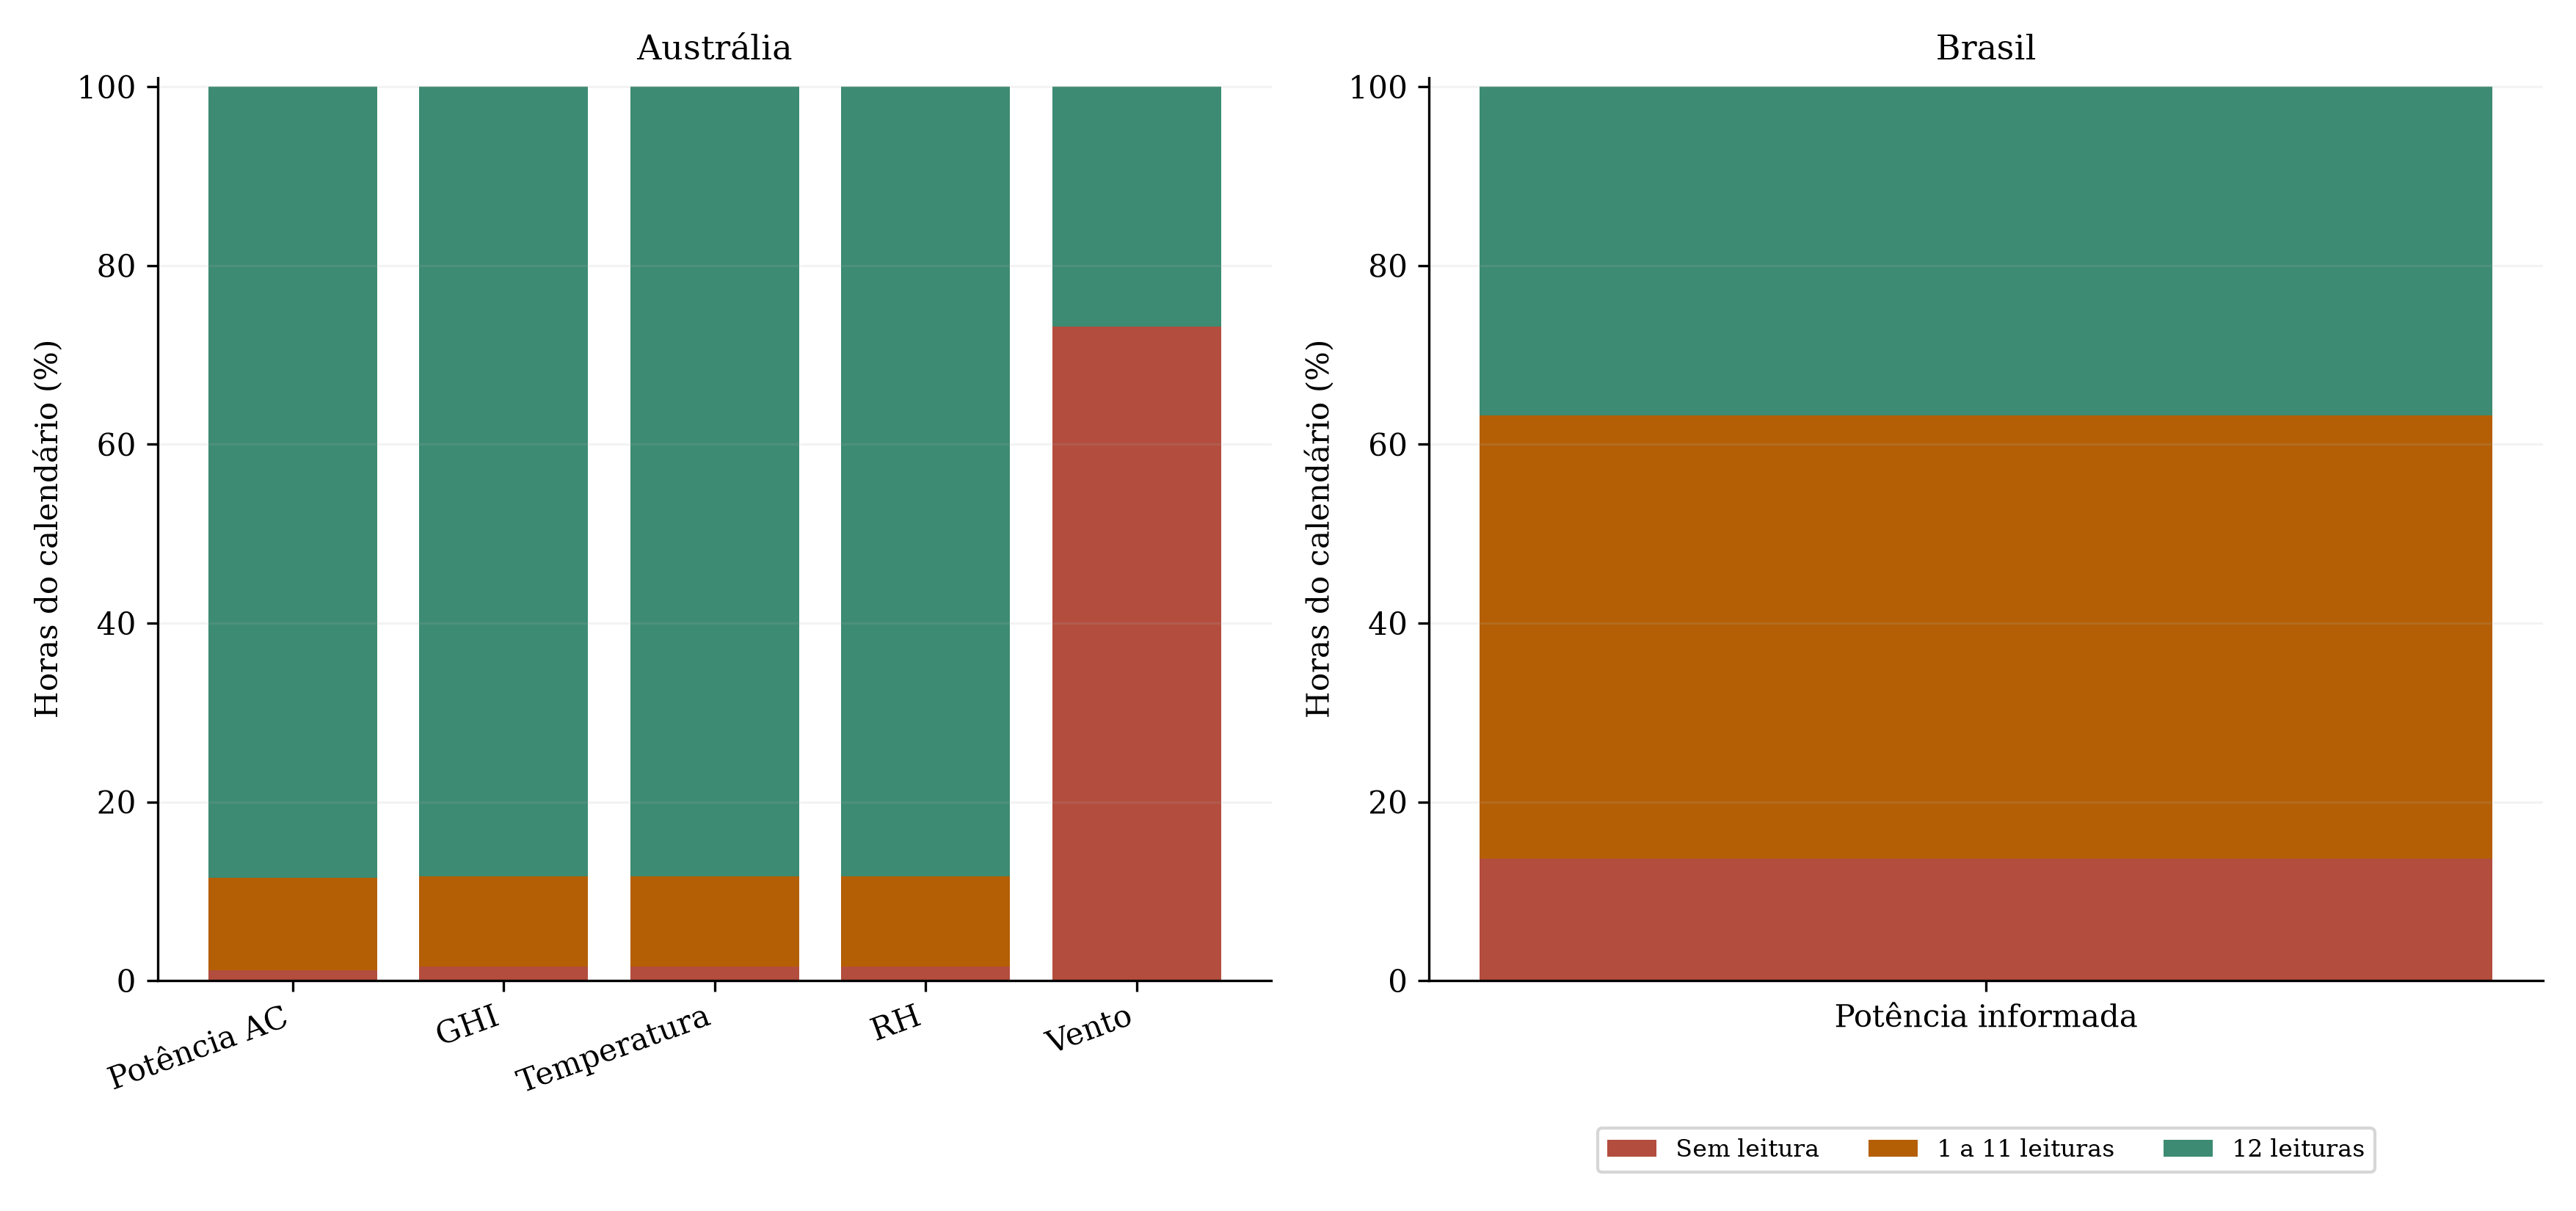

**Figura 3.3-H01 — Cobertura de cinco minutos das horas agregadas.** O resample horário usa a média dos valores presentes, como os autores, sem exigir doze amostras. A auditoria separa horas vazias, médias de 1–11 valores e médias de 12 valores. A Austrália exige AP/GHI/temperatura/RH/vento; o Brasil exige somente AP.

In [13]:
fig, ax = plt.subplots(1,2,figsize=(11.7,5.5))
for a,dom,labels in [(ax[0],'australia',nomes),(ax[1],'brasil',['Potência informada'])]:
    g = t['cobertura_5min_por_hora'].query('dominio == @dom'); bottom=np.zeros(len(g))
    for c,label,cor in [('horas_sem_leitura','Sem leitura',vermelho),('horas_1_a_11_leituras','1 a 11 leituras',laranja),('horas_com_12_leituras','12 leituras',verde)]:
        v=g[c].to_numpy()/g.horas.to_numpy()*100; a.bar(range(len(g)),v,bottom=bottom,label=label,color=cor); bottom+=v
    a.set_xticks(range(len(g)),labels,rotation=20,ha='right')
    a.set(title='Austrália' if dom=='australia' else 'Brasil',ylabel='Horas do calendário (%)',ylim=(0,101));a.grid(axis='y',alpha=.15)
ax[1].set_xticks([0], ['Potência informada'], rotation=0, ha='center')
ax[1].legend(loc='upper center',bbox_to_anchor=(.5,-.15),ncol=3)
salvar(fig,'fig_3_3_h01_cobertura_horaria','Cobertura de cinco minutos das horas agregadas',
       'O resample horário usa a média dos valores presentes, como os autores, sem exigir doze amostras. A auditoria separa horas vazias, médias de 1–11 valores e médias de 12 valores. A Austrália exige AP/GHI/temperatura/RH/vento; o Brasil exige somente AP.')


figura(1)

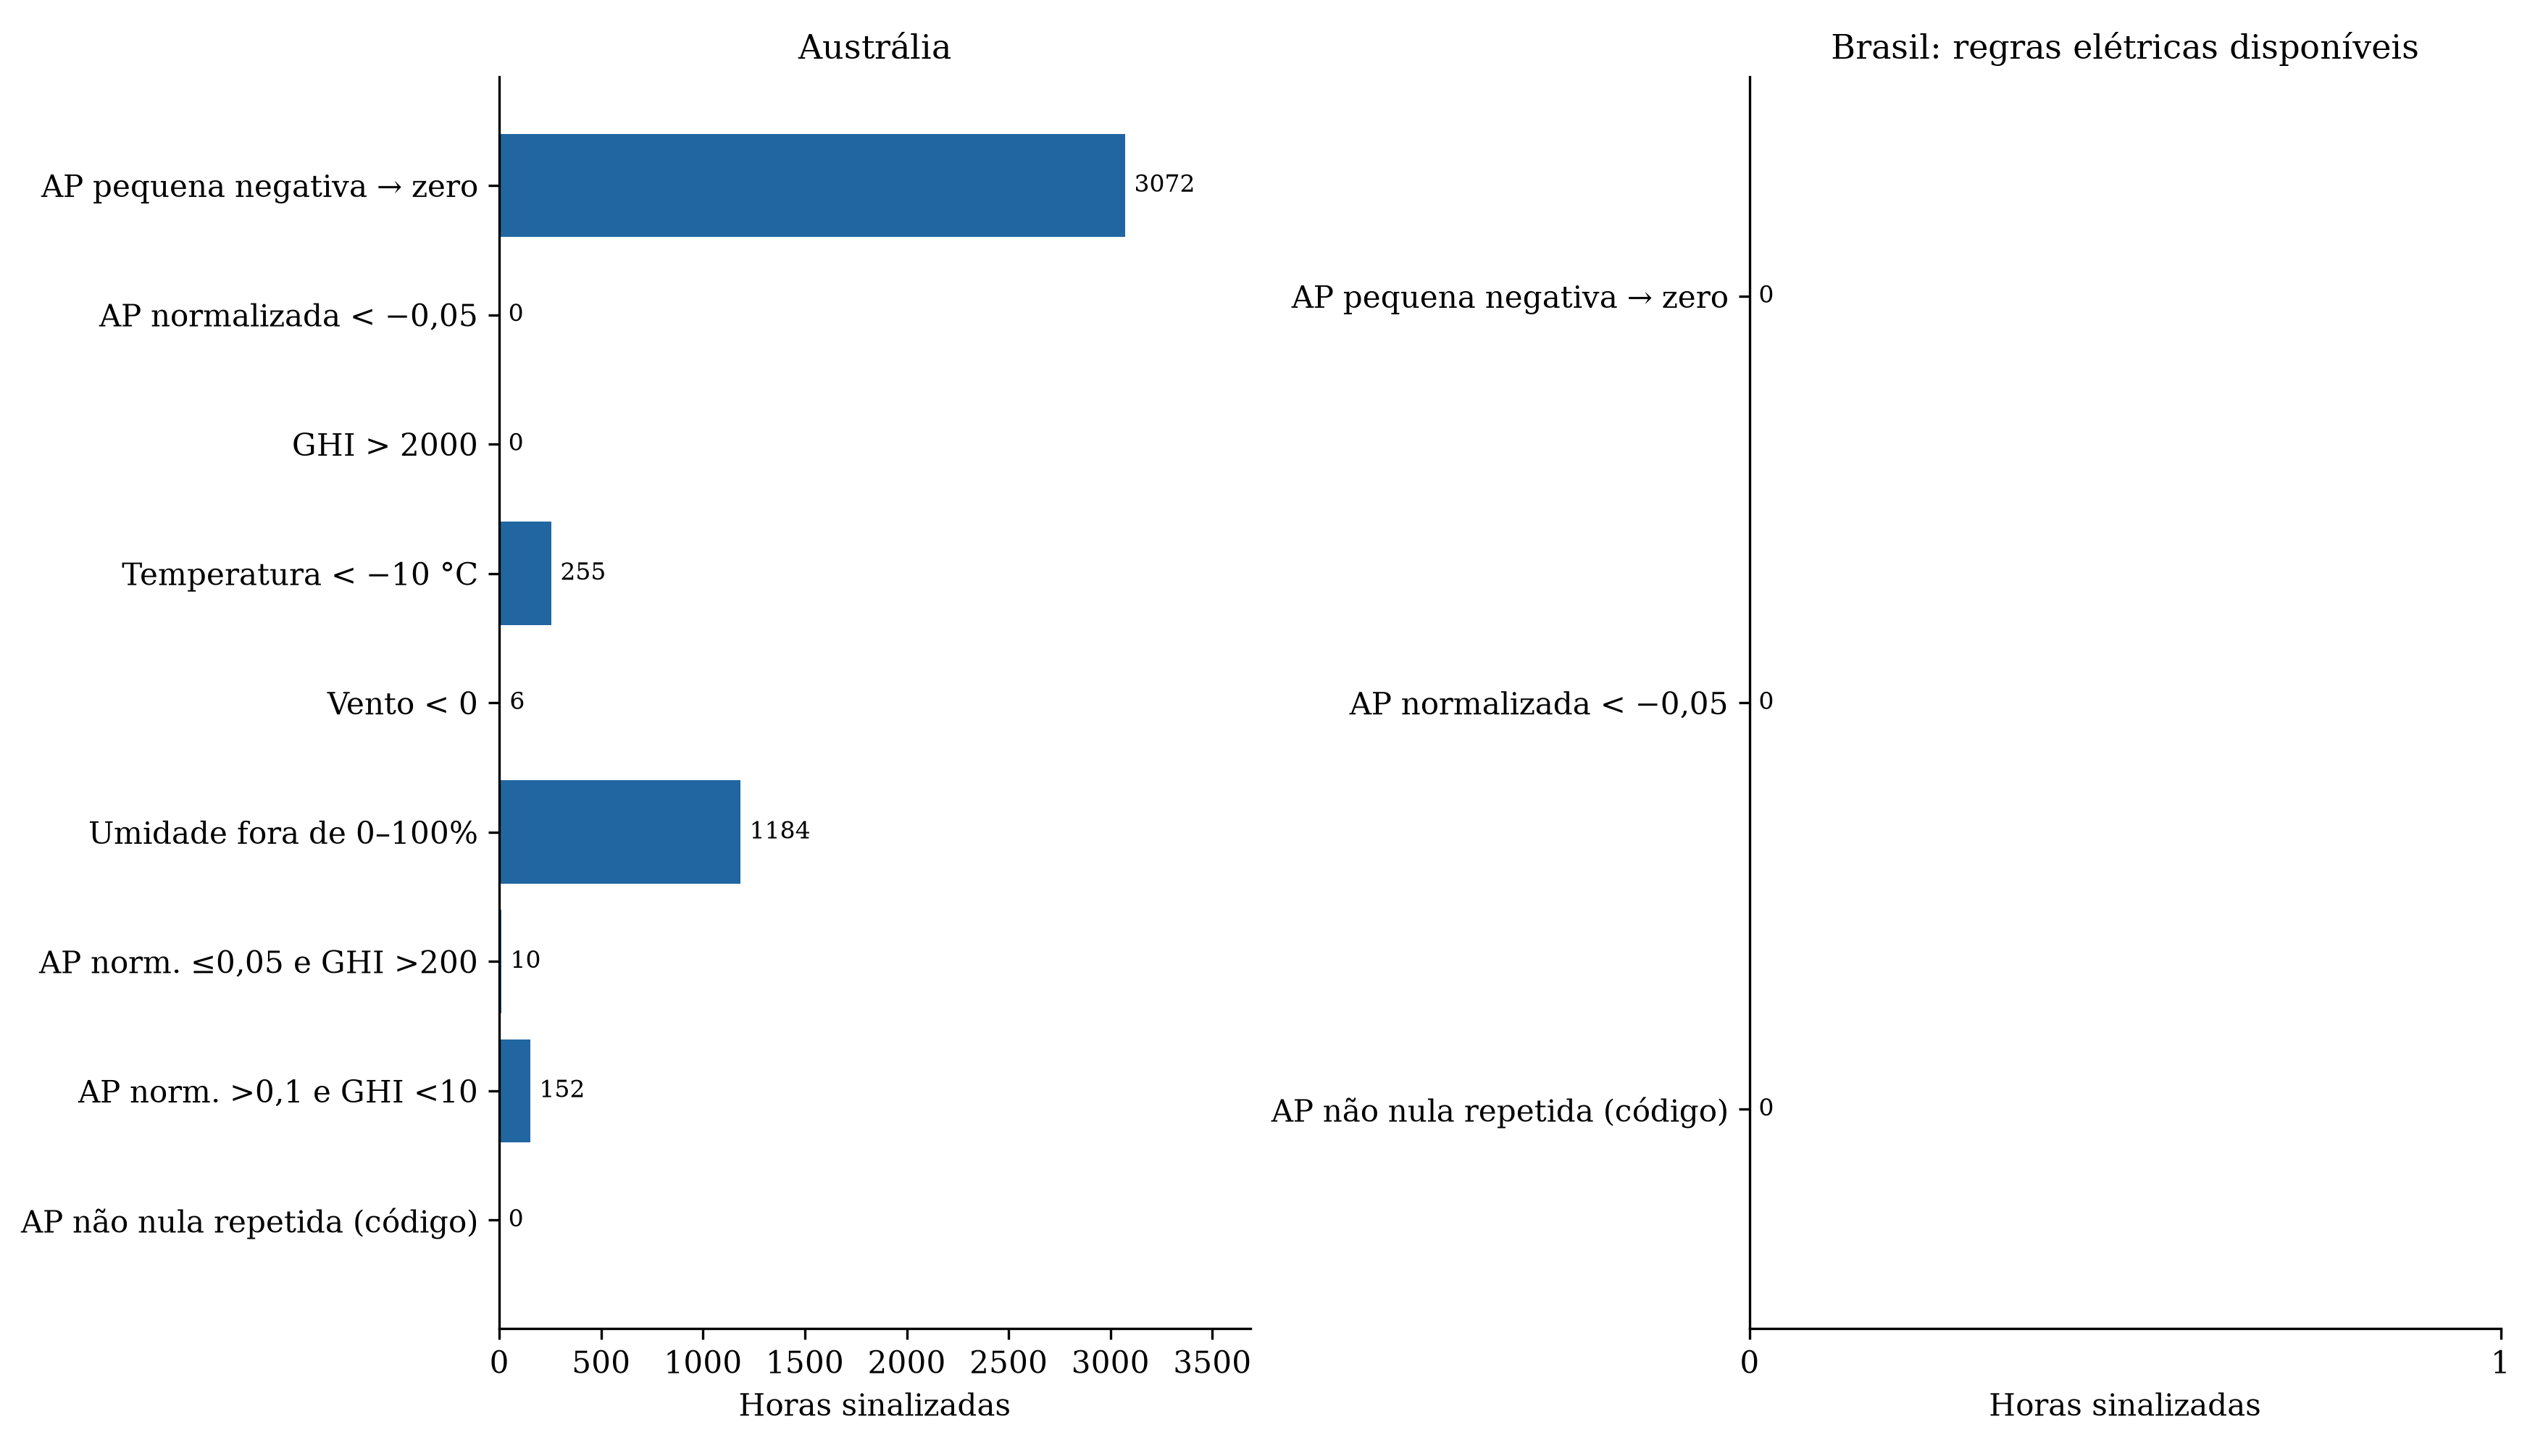

**Figura 3.3-H02 — Triagem dos canais disponíveis em cada domínio.** A Austrália aplica QC elétrico e meteorológico e os testes cruzados AP × GHI. O Brasil aplica somente QC elétrico, pois a fonte final é univariada e a escala do GHI local não foi confirmada. Vento incluído somente na Austrália, com valores negativos invalidados. Contagens podem se sobrepor e não demonstram qualidade física completa.

In [14]:
fig,ax=plt.subplots(1,2,figsize=(11.7,6.7))
labels={'potencia_negativa_entre_menos005_e_zero_convertida_zero':'AP pequena negativa → zero',
        'potencia_normalizada_menor_menos005':'AP normalizada < −0,05','ghi_maior_2000':'GHI > 2000',
        'temperatura_menor_menos10':'Temperatura < −10 °C','vento_negativo':'Vento < 0',
        'umidade_fora_0_100':'Umidade fora de 0–100%',
        'potencia_normalizada_ate005_ghi_acima200':'AP norm. ≤0,05 e GHI >200',
        'potencia_normalizada_acima01_ghi_abaixo10':'AP norm. >0,1 e GHI <10',
        'potencia_nao_nula_repetida_10_comparacoes':'AP não nula repetida (código)'}
for a,dom,cor in [(ax[0],'australia',azul),(ax[1],'brasil',laranja)]:
    g=t['regras_anomalias'].query('dominio == @dom');b=a.barh(range(len(g)),g.horas_sinalizadas,color=cor)
    a.bar_label(b,padding=3,fontsize=8);a.set_yticks(range(len(g)),[labels[c] for c in g.regra]);a.invert_yaxis()
    a.set(title='Austrália' if dom=='australia' else 'Brasil: regras elétricas disponíveis',xlabel='Horas sinalizadas');a.margins(x=.2)
    if not g.horas_sinalizadas.any():
        a.set_xlim(0, 1)
        a.set_xticks([0, 1])
salvar(fig,'fig_3_3_h02_anomalias','Triagem dos canais disponíveis em cada domínio',
       'A Austrália aplica QC elétrico e meteorológico e os testes cruzados AP × GHI. O Brasil aplica somente QC elétrico, pois a fonte final é univariada e a escala do GHI local não foi confirmada. Vento incluído somente na Austrália, com valores negativos invalidados. Contagens podem se sobrepor e não demonstram qualidade física completa.')


figura(2)

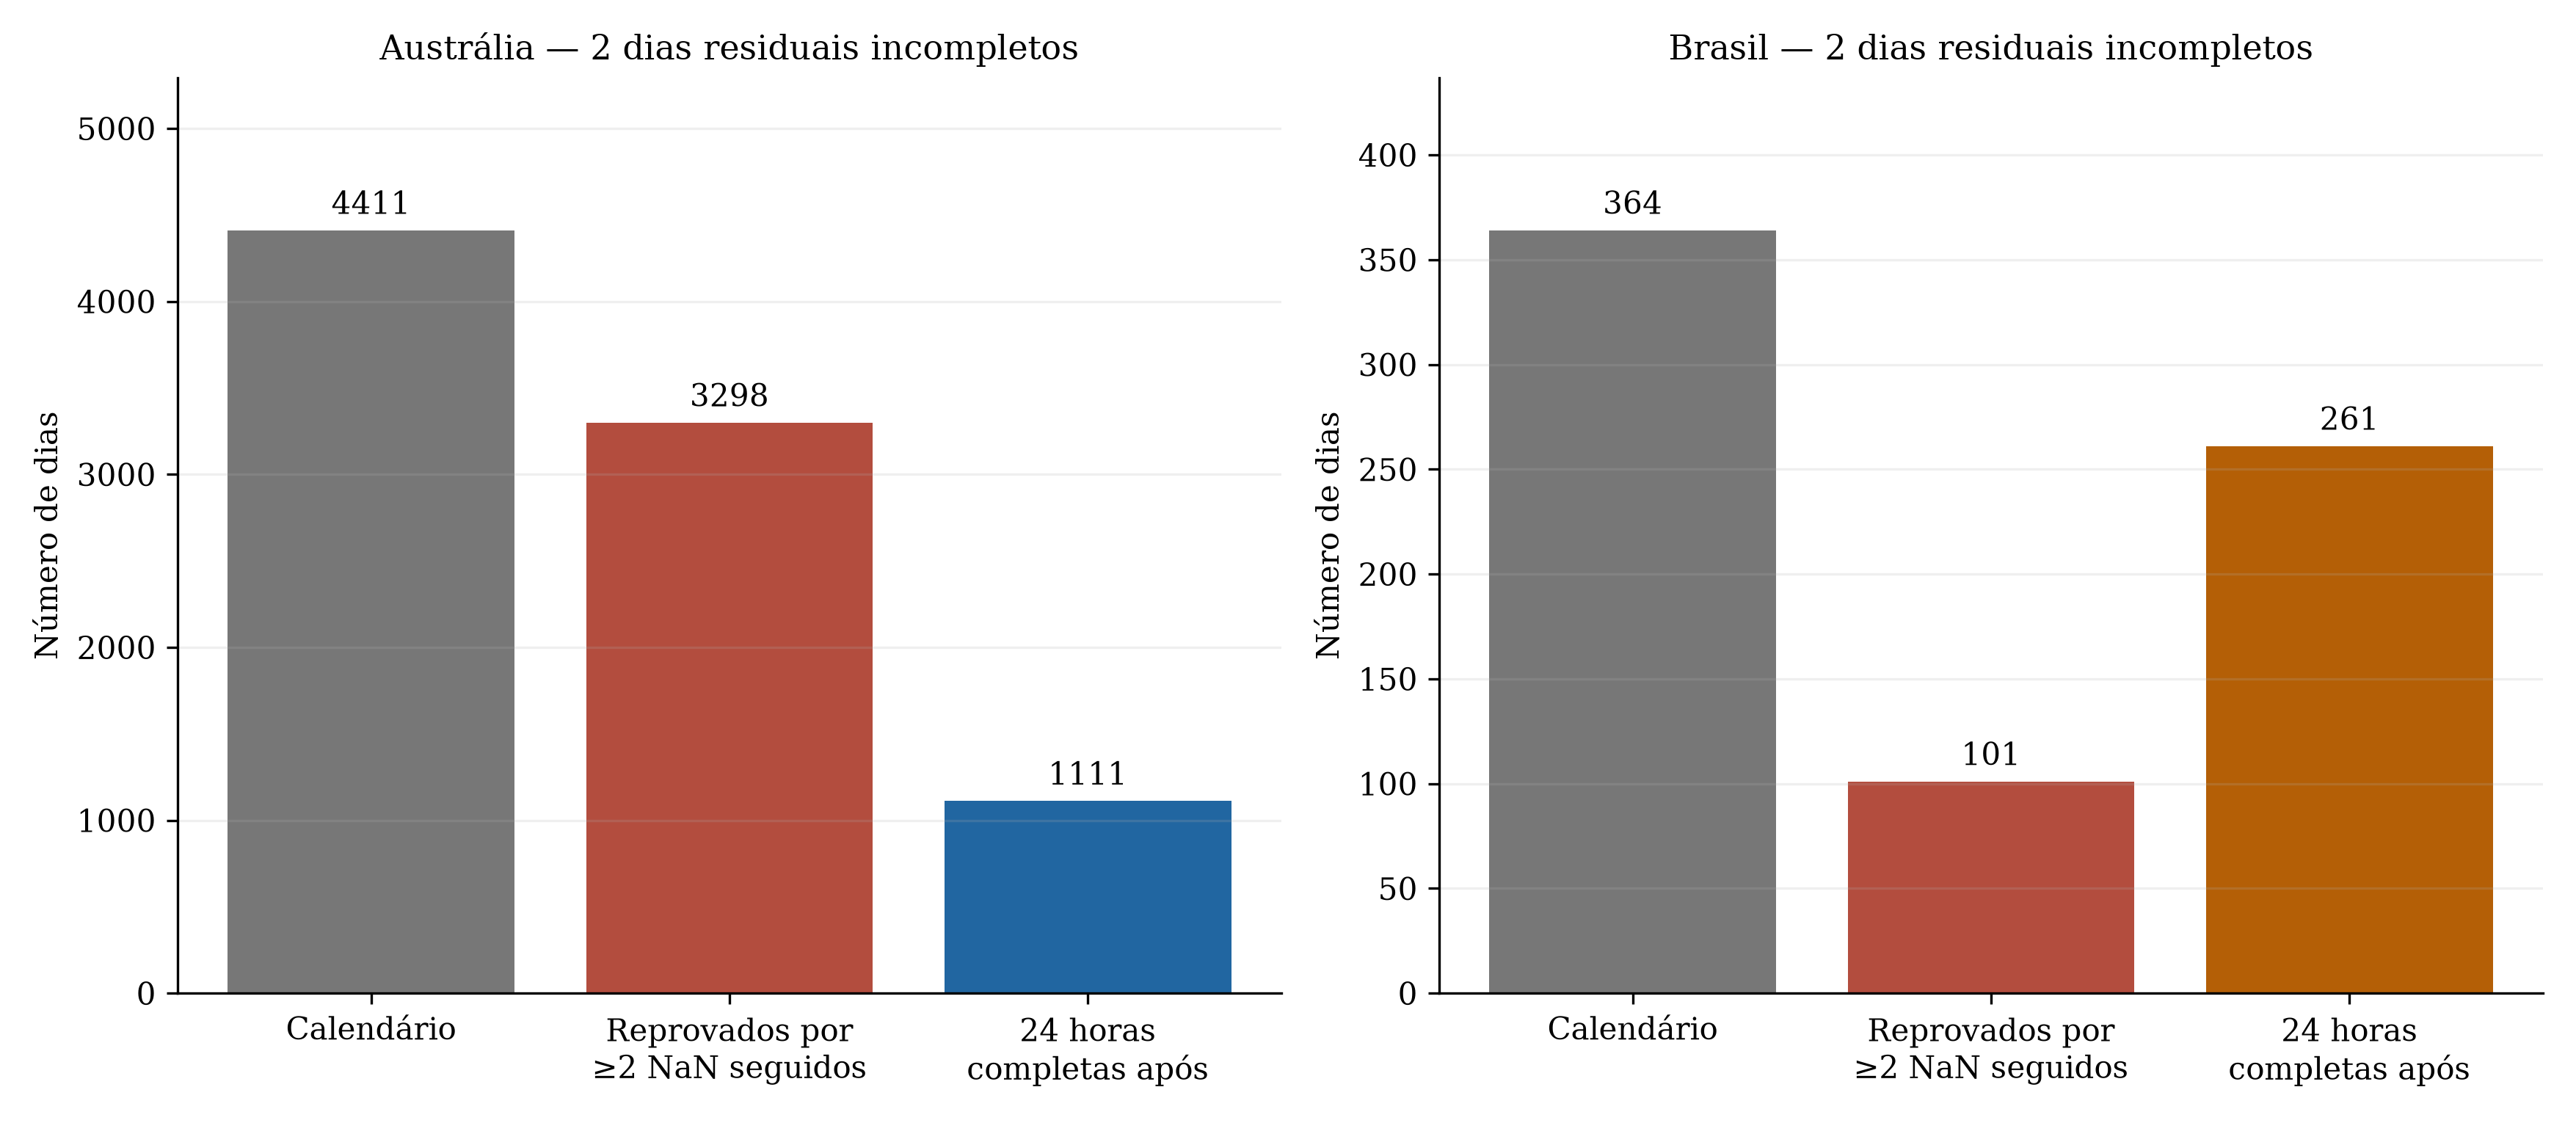

**Figura 3.3-H03 — Efeito da remoção de dias e interpolação de horas isoladas.** Um dia é reprovado quando há duas horas NaN consecutivas em qualquer coluna exigida. A contagem segue a varredura cronológica do código; a detecção pode alcançar meia-noite. Lacunas residuais nas bordas são mantidas sem extrapolação. Dias de calendário, reprovados e completos são etapas, não parcelas somáveis.

In [15]:
fig,ax=plt.subplots(1,2,figsize=(11.7,5.1))
for a,dom,cor in [(ax[0],'australia',azul),(ax[1],'brasil',laranja)]:
    g=t['dias_auditados'].query('dominio == @dom')
    rejeita=int(g.dia_reprovado_duas_nan.sum());completo=int(g.dia_24h_completo.sum());residual=len(g)-rejeita-completo
    bars=a.bar(range(3),[len(g),rejeita,completo],color=['#777777',vermelho,cor]);a.bar_label(bars,padding=3)
    a.set_xticks(range(3),['Calendário','Reprovados por\n≥2 NaN seguidos','24 horas\ncompletas após'])
    a.set(title=('Austrália' if dom=='australia' else 'Brasil')+f' — {residual} dias residuais incompletos',ylabel='Número de dias');a.margins(y=.2);a.grid(axis='y',alpha=.2)
salvar(fig,'fig_3_3_h03_dias','Efeito da remoção de dias e interpolação de horas isoladas',
       'Um dia é reprovado quando há duas horas NaN consecutivas em qualquer coluna exigida. A contagem segue a varredura cronológica do código; a detecção pode alcançar meia-noite. Lacunas residuais nas bordas são mantidas sem extrapolação. Dias de calendário, reprovados e completos são etapas, não parcelas somáveis.')


figura(3)

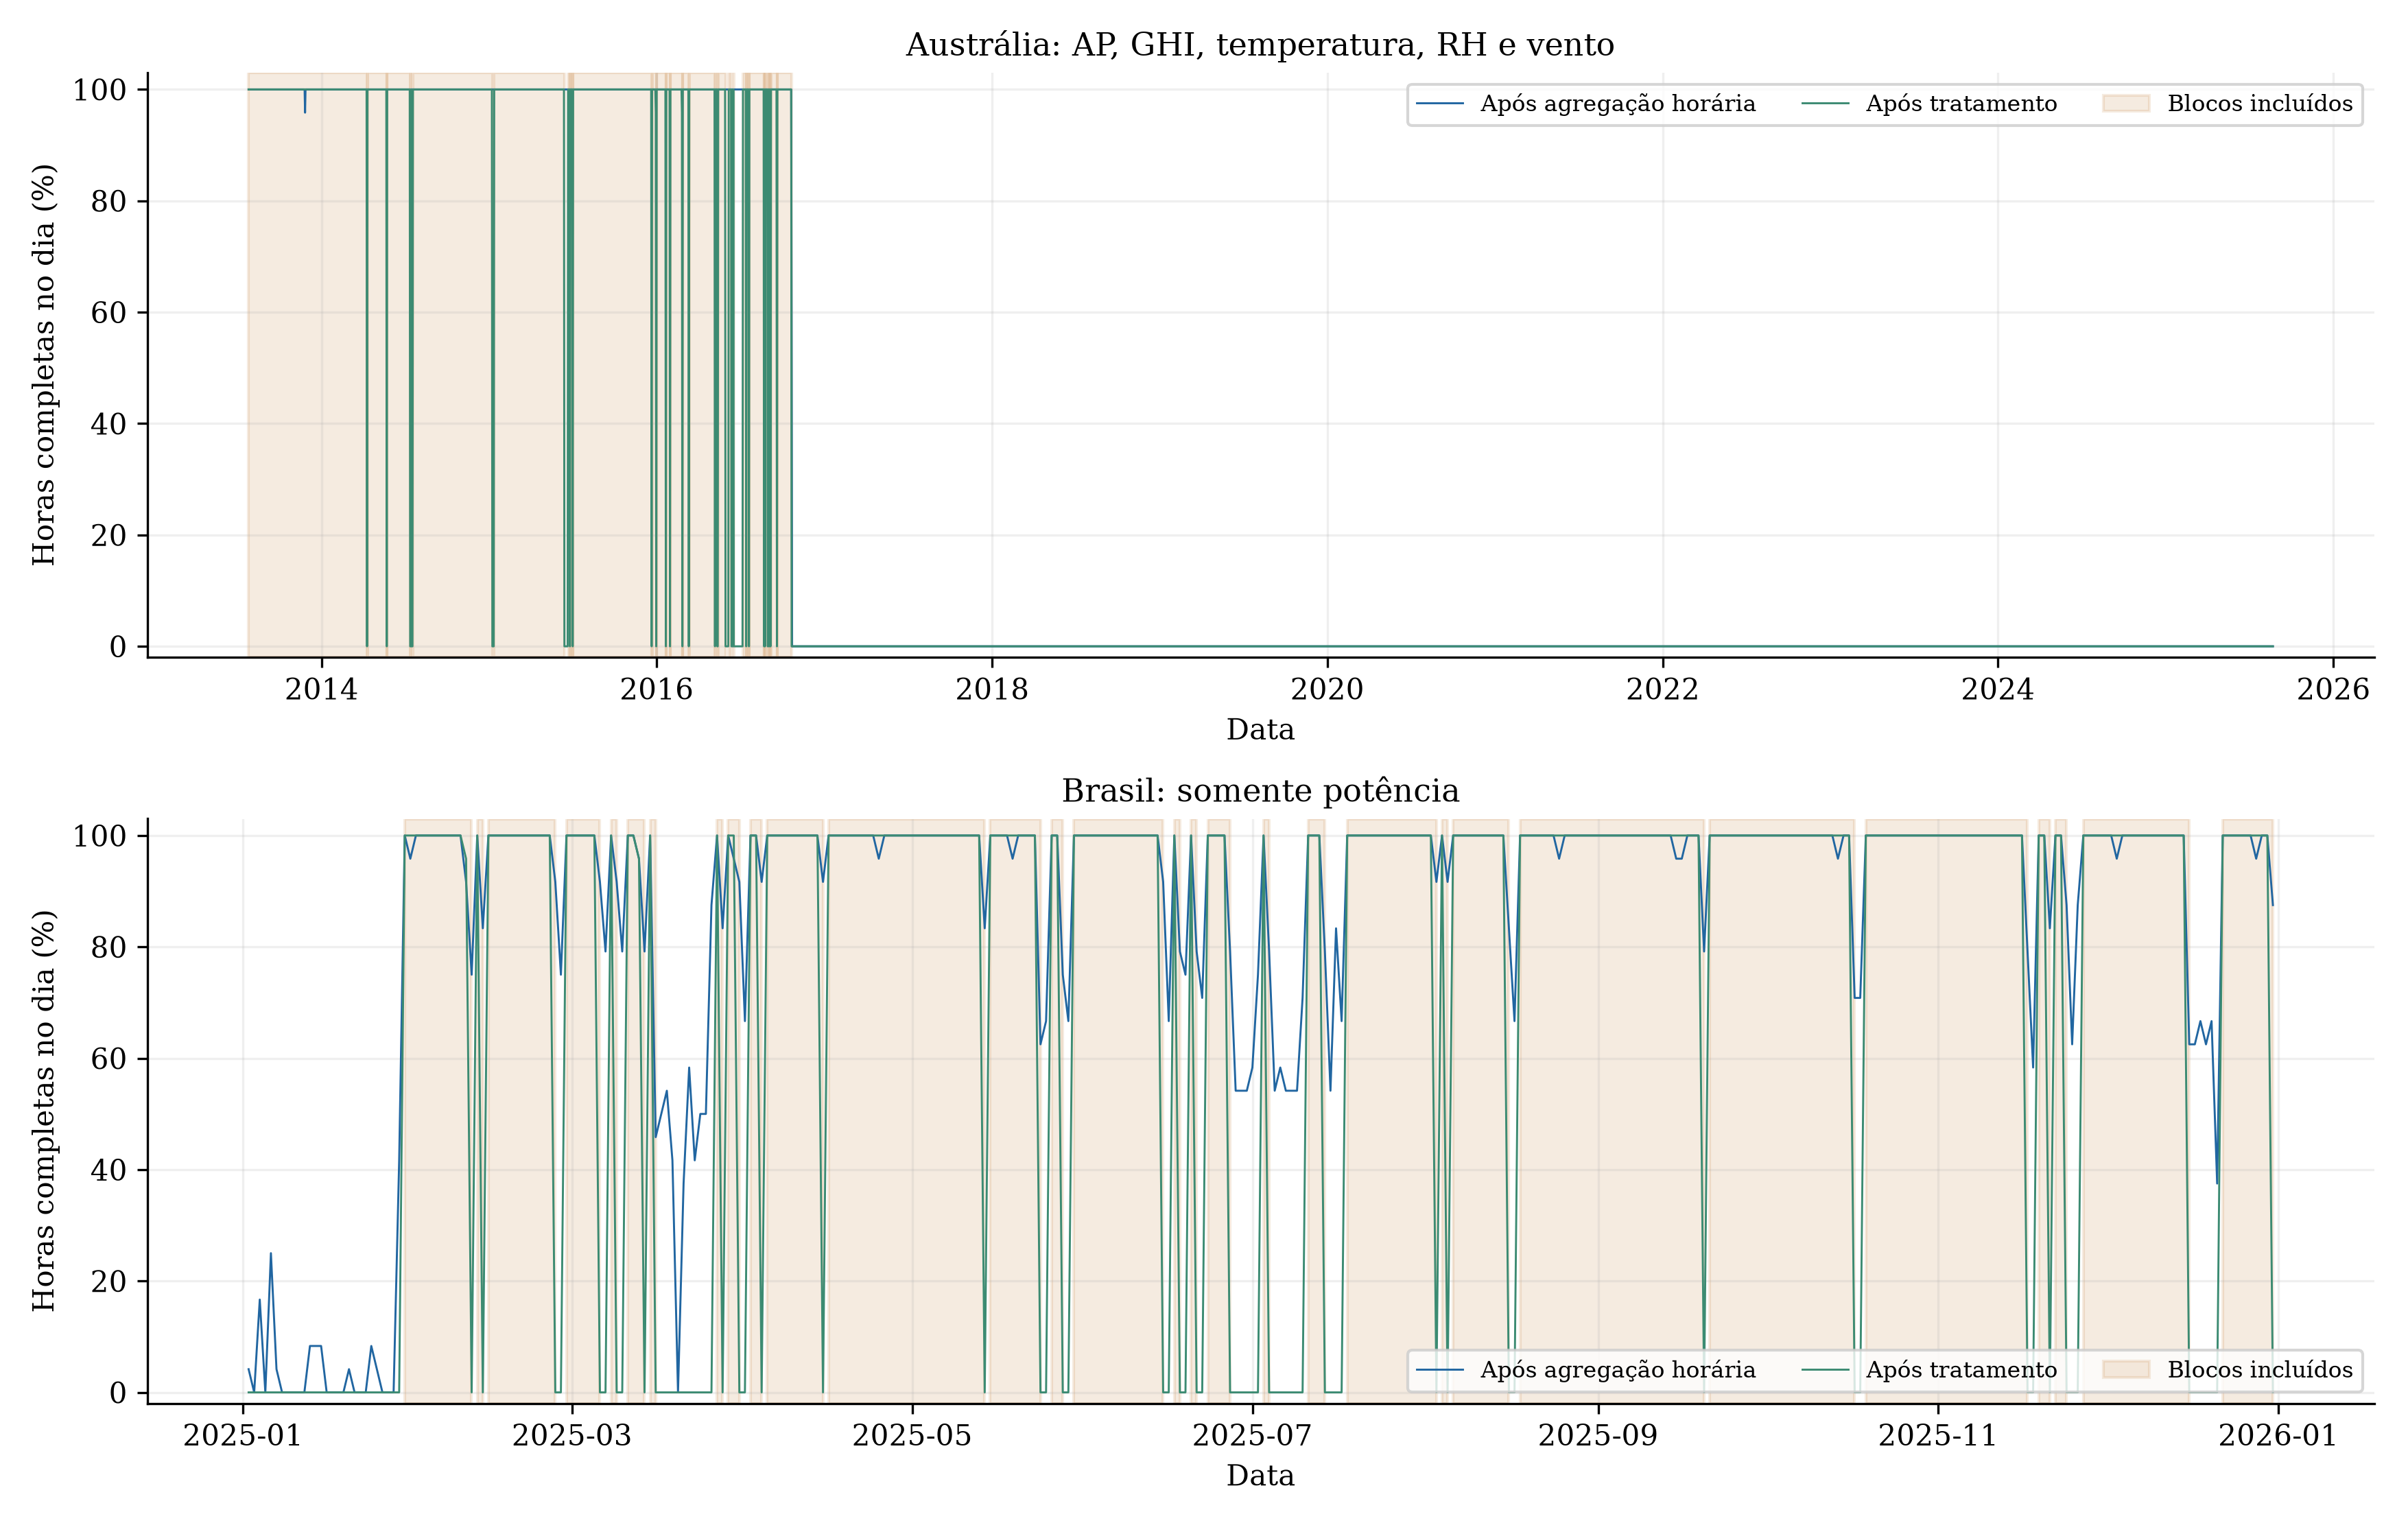

**Figura 3.3-H04 — Todos os blocos horários incluídos na base final.** As faixas mostram todos os blocos elegíveis após QC, descarte de dias e interpolação isolada. AU exige as cinco entradas e BR somente AP. As interrupções são preservadas; os blocos não são concatenados para formar janelas através de lacunas. Continuidade das médias não comprova doze amostras originais por hora.

In [16]:
fig,ax=plt.subplots(2,1,figsize=(11.7,7.4))
for a,dom in zip(ax,['australia','brasil']):
    cols=COLUNAS_POR_DOMINIO[dom]
    for dados,label,cor in [(processamento['horarios'][dom],'Após agregação horária',azul),
                            (processamento['tratados'][dom],'Após tratamento',verde)]:
        serie=dados[cols].notna().all(axis=1).resample('D').mean()*100
        a.plot(serie.index,serie,lw=.7,label=label,color=cor)
    for i,b in processamento['blocos'][dom].iterrows():
        a.axvspan(b.inicio,b.fim+pd.Timedelta(hours=1),color=laranja,alpha=.12,
                  label='Blocos incluídos' if i==0 else None)
    a.set(title='Austrália: AP, GHI, temperatura, RH e vento' if dom=='australia' else 'Brasil: somente potência',
          ylabel='Horas completas no dia (%)',xlabel='Data',ylim=(-2,103))
    a.legend(ncol=3);a.grid(alpha=.2)
salvar(fig,'fig_3_3_h04_selecao_blocos','Todos os blocos horários incluídos na base final',
       'As faixas mostram todos os blocos elegíveis após QC, descarte de dias e interpolação isolada. AU exige as cinco entradas e BR somente AP. As interrupções são preservadas; os blocos não são concatenados para formar janelas através de lacunas. Continuidade das médias não comprova doze amostras originais por hora.')
figura(4)

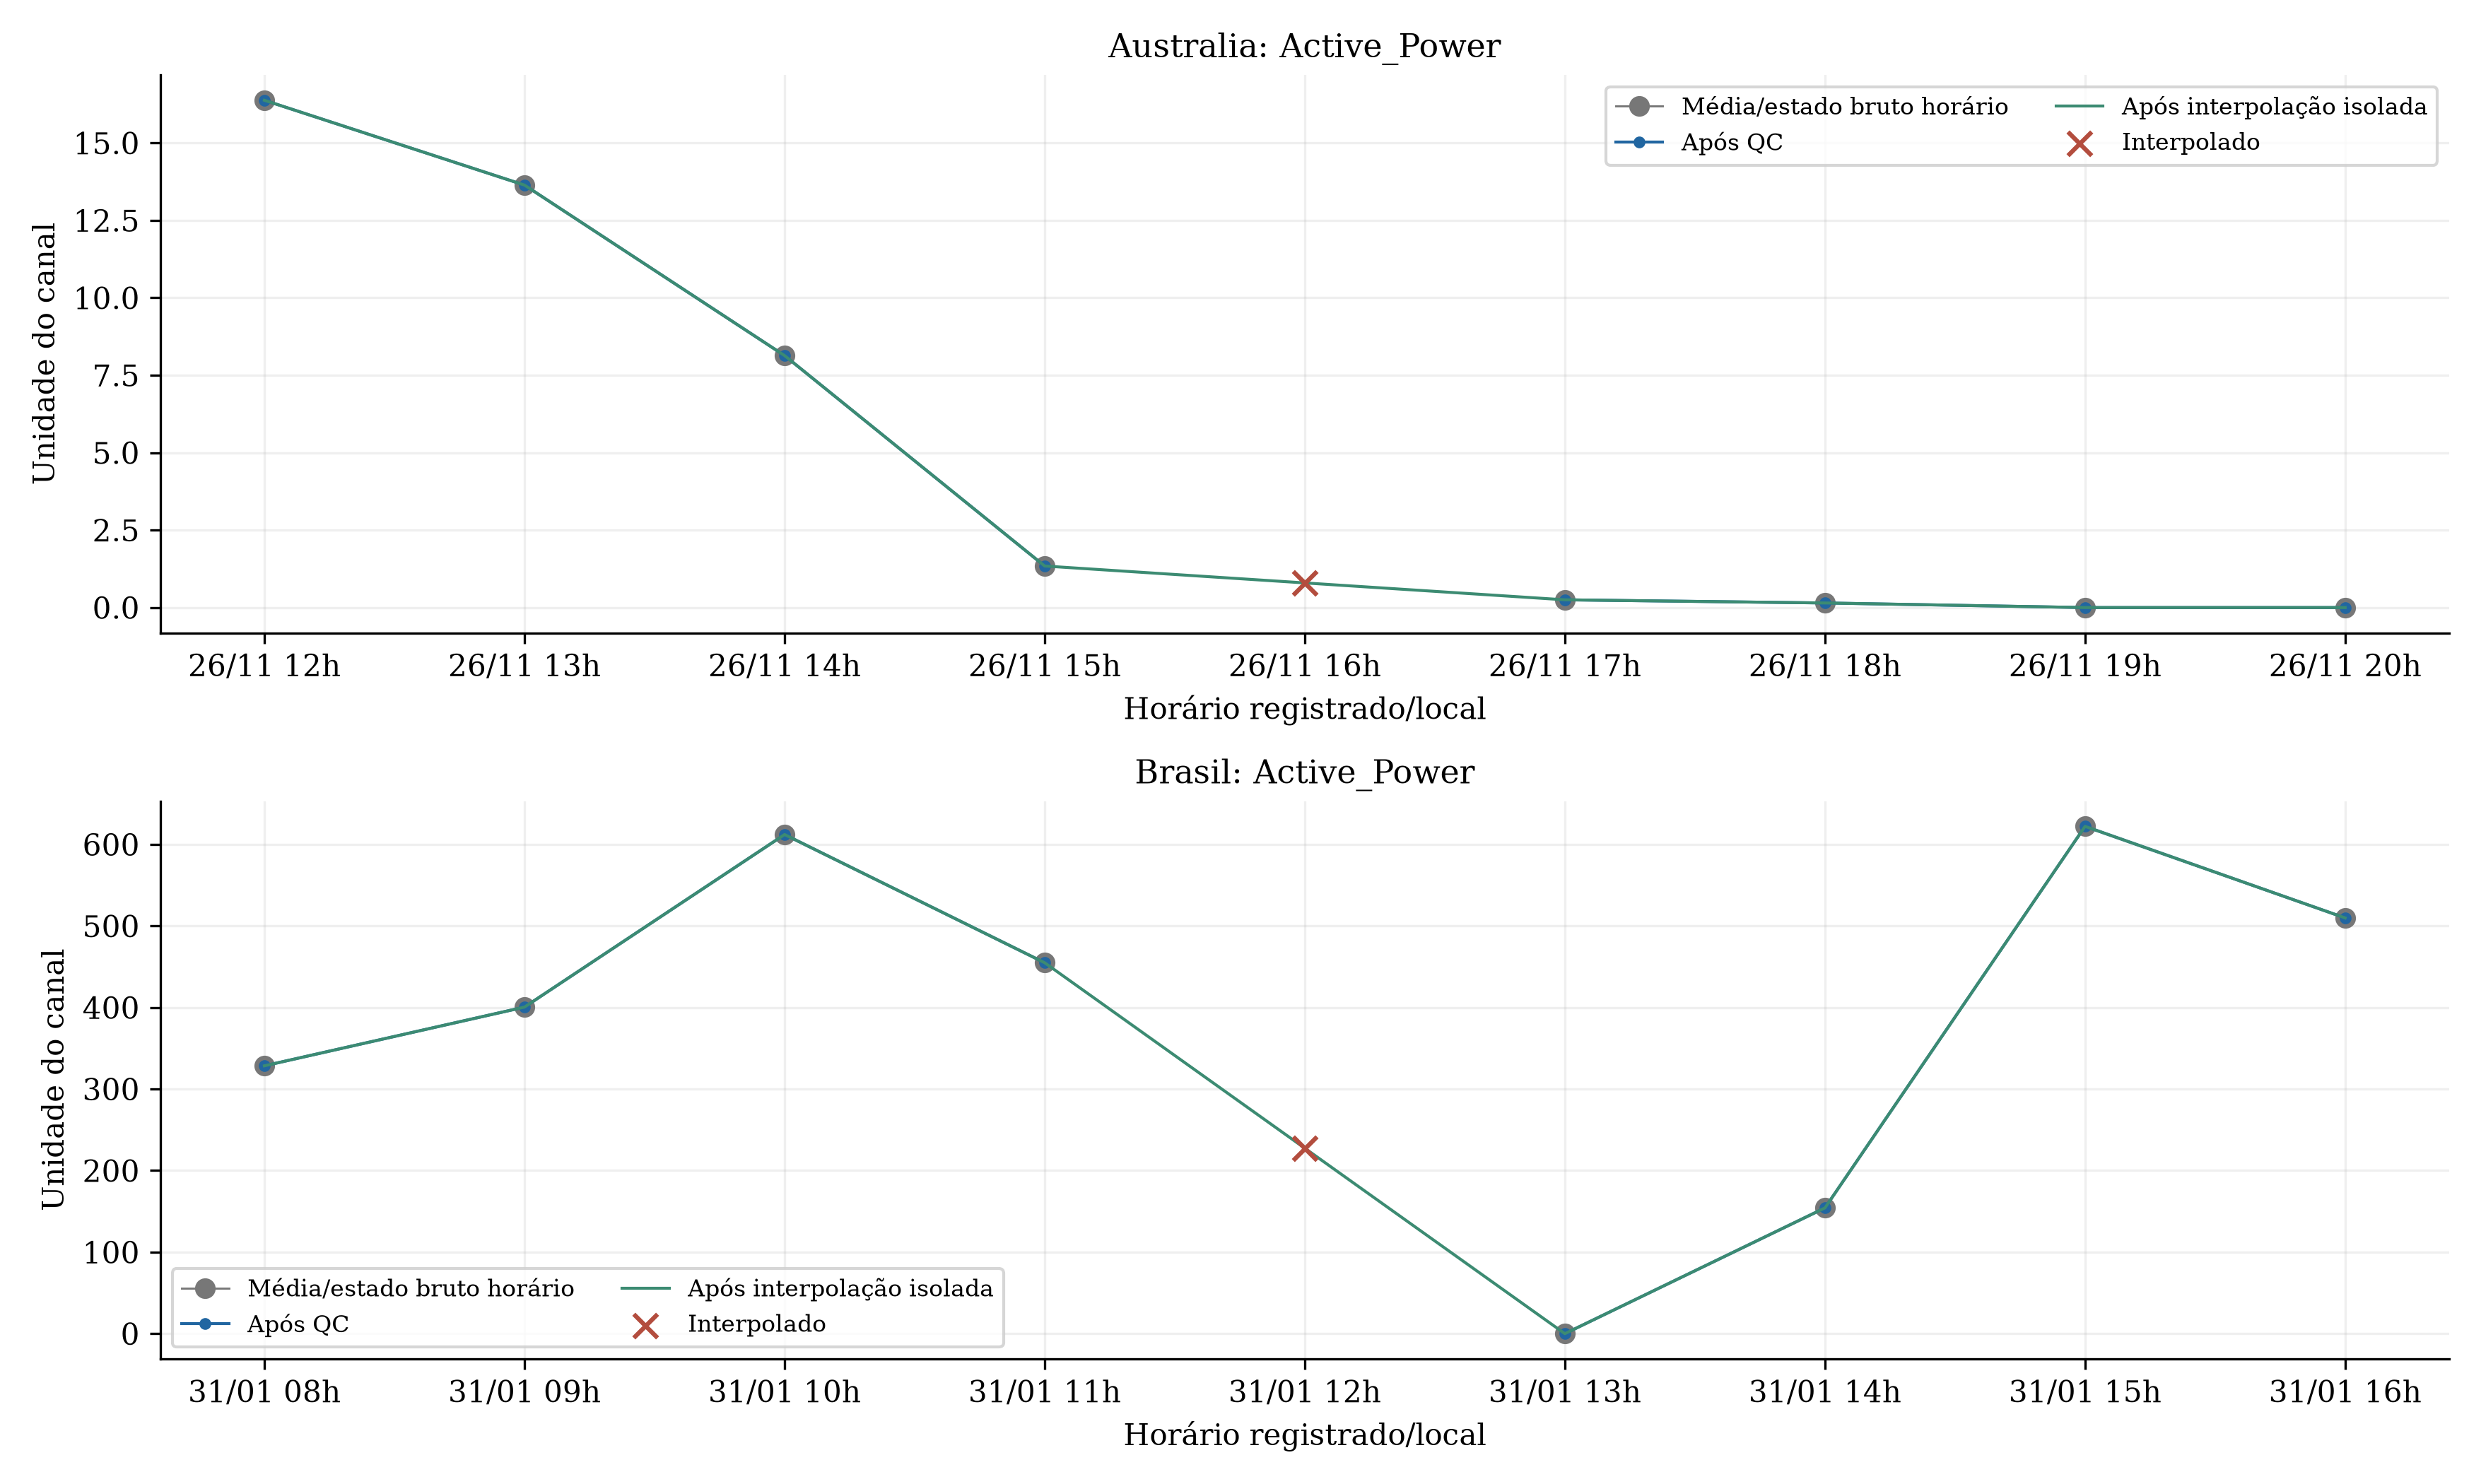

**Figura 3.3-H05 — Exemplos de preenchimento de uma hora isolada.** Só se preenche uma lacuna inteira de uma hora com duas bordas válidas. A estimativa é retrospectiva e passa a estar disponível ao término da hora da borda direita. A máscara exportada identifica alvos interpolados. Esses exemplos não constituem validação quantitativa da precisão da imputação.

In [17]:
fig,ax=plt.subplots(2,1,figsize=(11.7,7))
for a,dom in zip(ax,['australia','brasil']):
    cols=COLUNAS_POR_DOMINIO[dom];m=processamento['imputados'][dom]
    if not m[cols].any().any():
        a.text(.5,.5,'Nenhuma hora interpolada neste cenário',ha='center',va='center',transform=a.transAxes)
        continue
    c='Active_Power' if m.Active_Power.any() else next(c for c in cols if m[c].any())
    data=m.index[m[c]][0];ini,fim=data-pd.Timedelta(hours=4),data+pd.Timedelta(hours=4)
    bruto=processamento['horarios'][dom].loc[ini:fim,c];qc=processamento['limpos'][dom].loc[ini:fim,c];final=processamento['tratados'][dom].loc[ini:fim,c]
    a.plot(bruto.index,bruto,marker='o',color='#777777',lw=.7,label='Média/estado bruto horário')
    a.plot(qc.index,qc,marker='.',color=azul,lw=1,label='Após QC')
    a.plot(final.index,final,color=verde,lw=1,label='Após interpolação isolada')
    a.scatter([data],[final.loc[data]],s=65,color=vermelho,marker='x',zorder=5,label='Interpolado')
    a.set(title=f'{dom.capitalize()}: {c}',ylabel='Unidade do canal',xlabel='Horário registrado/local')
    a.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %Hh'));a.legend(ncol=2);a.grid(alpha=.2)
salvar(fig,'fig_3_3_h05_interpolacao','Exemplos de preenchimento de uma hora isolada',
       'Só se preenche uma lacuna inteira de uma hora com duas bordas válidas. A estimativa é retrospectiva e passa a estar disponível ao término da hora da borda direita. A máscara exportada identifica alvos interpolados. Esses exemplos não constituem validação quantitativa da precisão da imputação.')


figura(5)

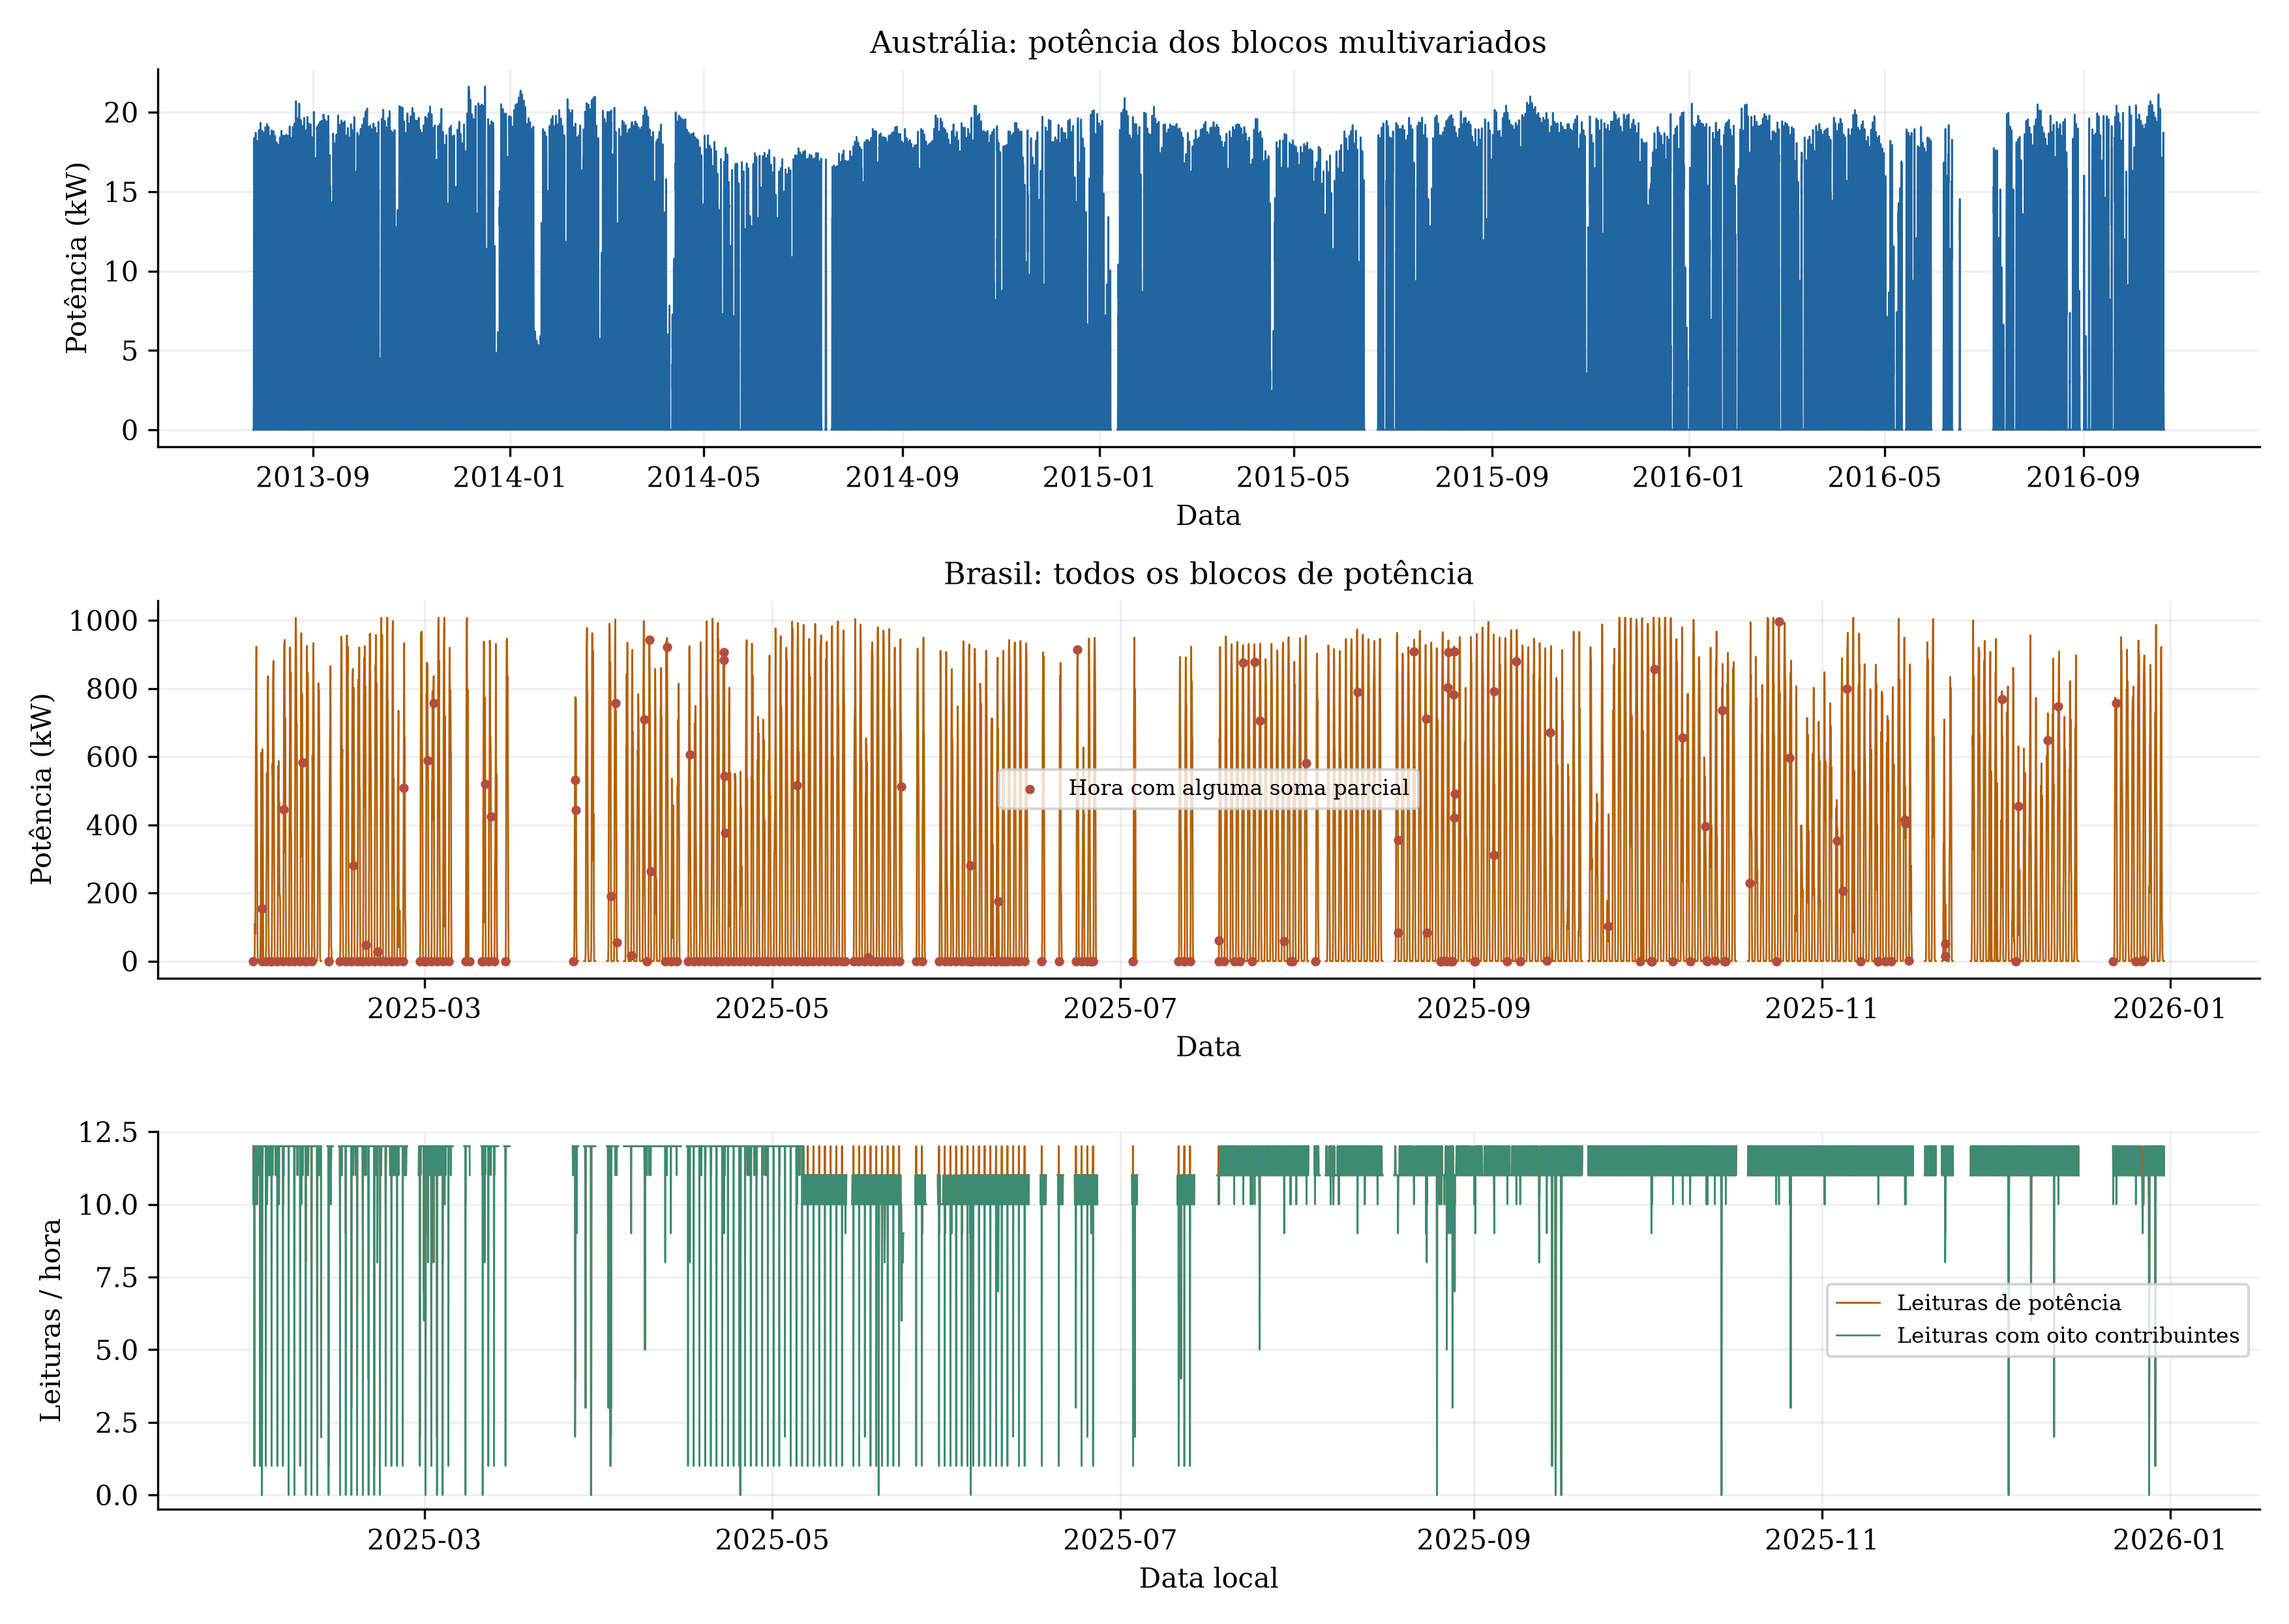

**Figura 3.3-H06 — Séries de todos os blocos e cobertura brasileira.** Cada linha é desenhada dentro de seu bloco, sem ligar períodos separados. Potência brasileira é soma das parcelas disponíveis; horas com contribuição parcial e menos de doze leituras permanecem identificadas. O maior bloco de 33 dias não limita os demais blocos aproveitados.

In [18]:
fig,ax=plt.subplots(3,1,figsize=(11.7,8.3))
for a,dom,cor in [(ax[0],'australia',azul),(ax[1],'brasil',laranja)]:
    s=processamento['frames'][dom]
    for _,g in s.groupby('bloco_id',sort=False):
        a.plot(g.index,g.Active_Power,lw=.65,color=cor)
    a.set(title=('Austrália: potência dos blocos multivariados' if dom=='australia' else 'Brasil: todos os blocos de potência'),
          ylabel='Potência (kW)',xlabel='Data')
s=processamento['frames']['brasil']
par=s.n_leituras_soma_parcial.gt(0)
ax[1].scatter(s.index[par],s.loc[par,'Active_Power'],s=6,color=vermelho,
              label='Hora com alguma soma parcial',zorder=4)
ax[1].legend()
for i,(_,g) in enumerate(s.groupby('bloco_id',sort=False)):
    ax[2].plot(g.index,g.n_5min_Active_Power,lw=.7,color=laranja,
                label='Leituras de potência' if i==0 else None)
    ax[2].plot(g.index,g.n_leituras_oito_inversores,lw=.65,color=verde,
                label='Leituras com oito contribuintes' if i==0 else None)
ax[2].set(ylabel='Leituras / hora',xlabel='Data local',ylim=(-.5,12.5));ax[2].legend()
for a in ax:a.grid(alpha=.2)
salvar(fig,'fig_3_3_h06_series','Séries de todos os blocos e cobertura brasileira',
       'Cada linha é desenhada dentro de seu bloco, sem ligar períodos separados. Potência brasileira é soma das parcelas disponíveis; horas com contribuição parcial e menos de doze leituras permanecem identificadas. O maior bloco de 33 dias não limita os demais blocos aproveitados.')
figura(6)

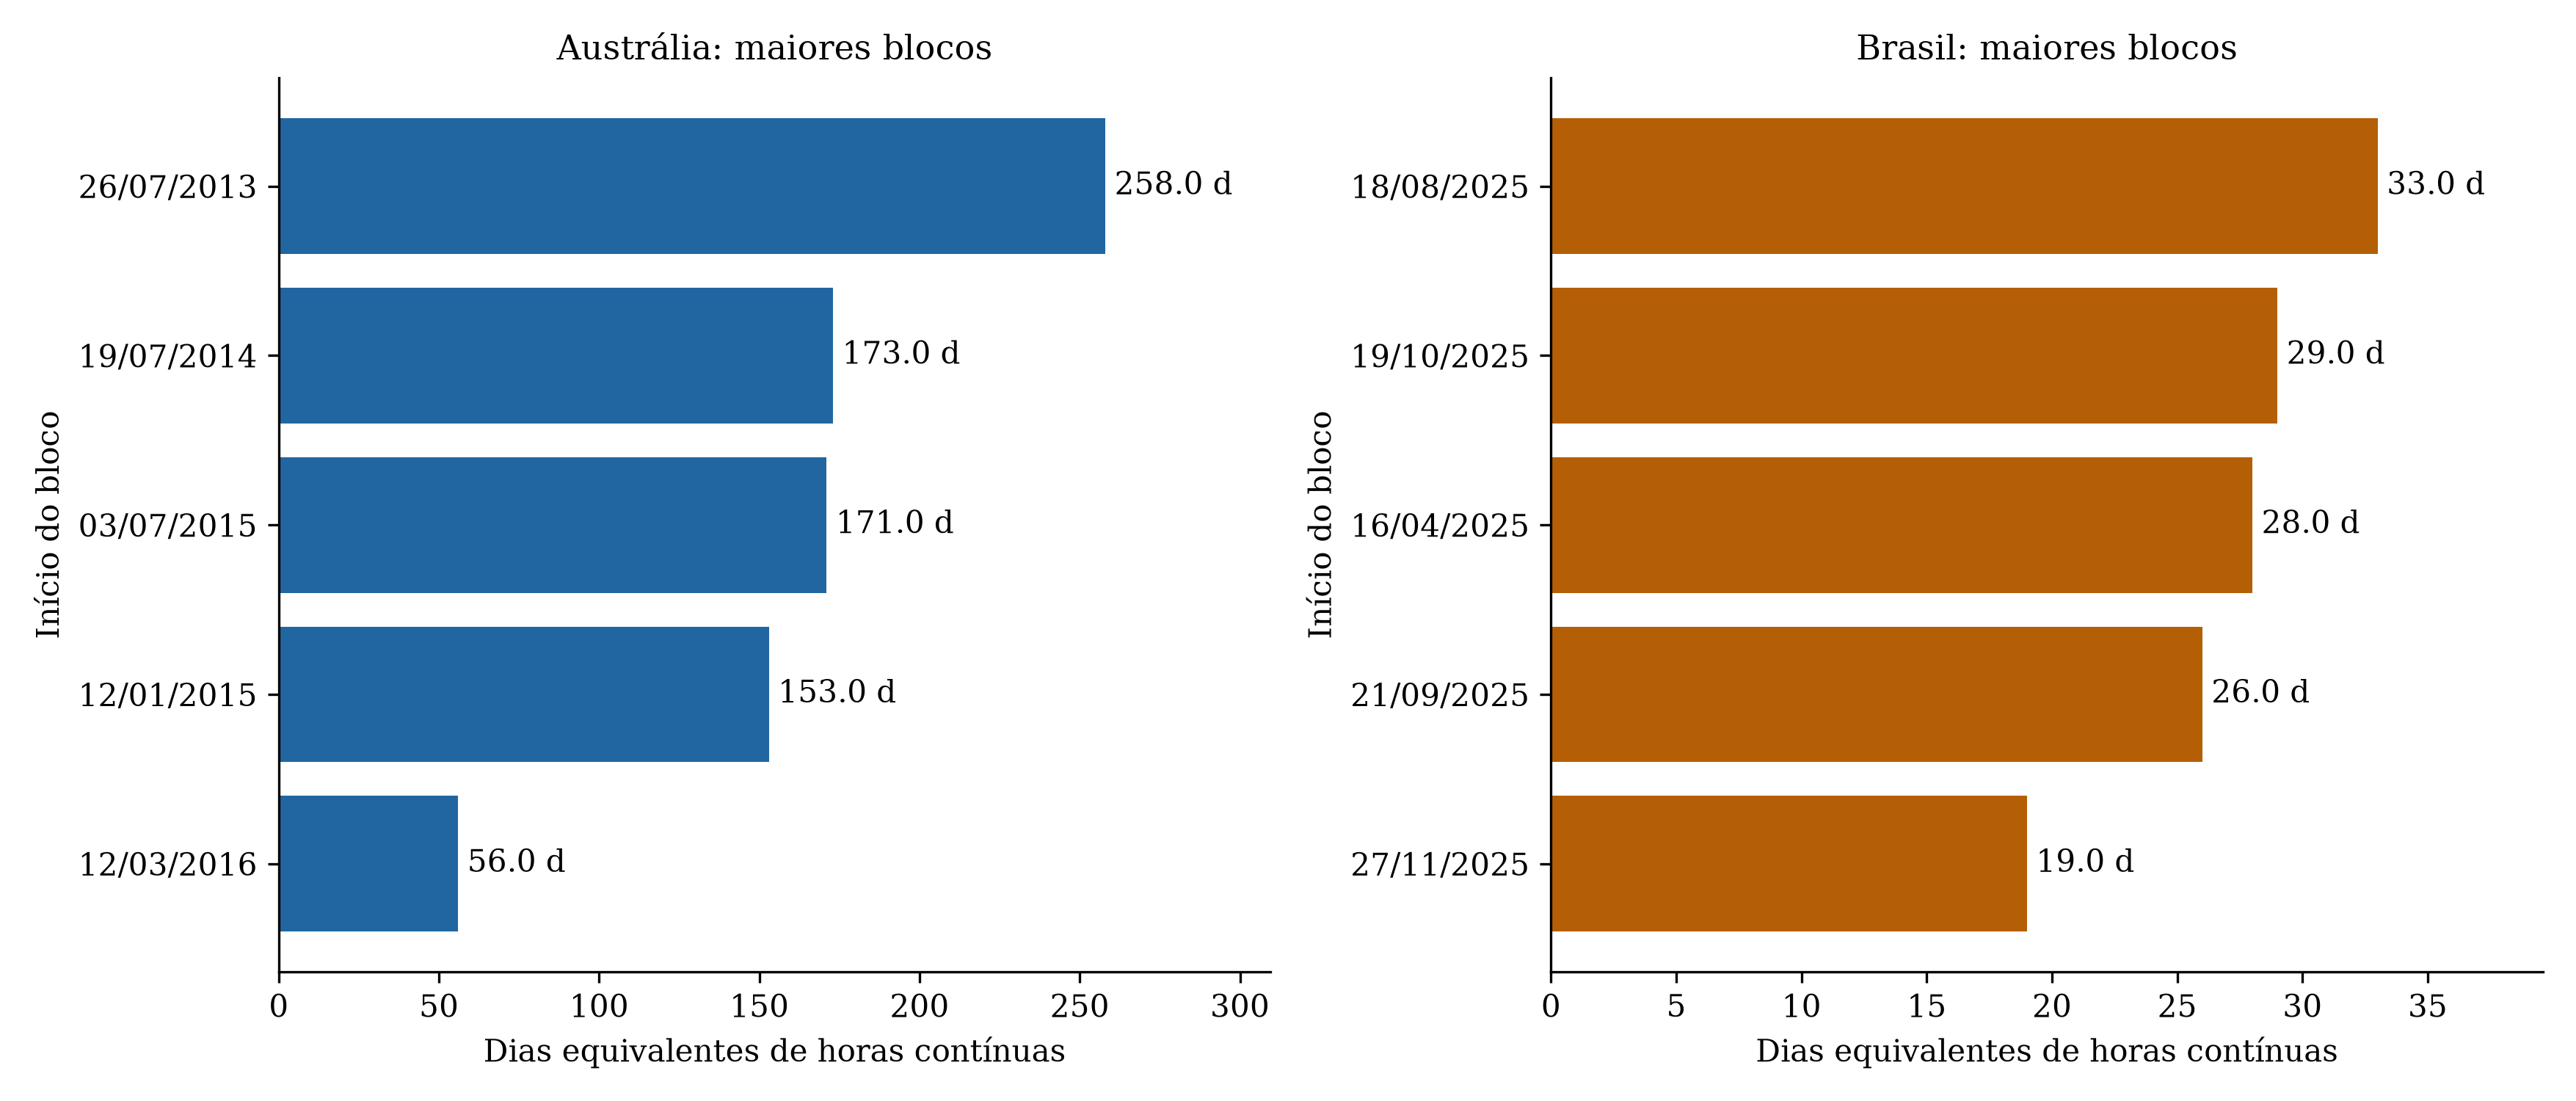

**Figura 3.3-H07 — Comparação dos maiores blocos após o tratamento horário.** Duração de cobertura = número de horas / 24. Os blocos são detectados por relógio regular, sem concatenar dias separados. Todos os blocos são exportados e identificados. Os cinco maiores são apresentados como diagnóstico, sem excluir os menores.

In [19]:
fig,ax=plt.subplots(1,2,figsize=(11.7,5))
for a,dom,cor in [(ax[0],'australia',azul),(ax[1],'brasil',laranja)]:
    g=t[dom+'_blocos'].nlargest(5,'horas').sort_values('horas')
    b=a.barh(range(len(g)),g.dias_equivalentes,color=cor)
    a.bar_label(b,labels=[f'{n:.1f} d' for n in g.dias_equivalentes],padding=3)
    a.set_yticks(range(len(g)),[pd.Timestamp(d).strftime('%d/%m/%Y') for d in g.inicio])
    a.set(title='Austrália: maiores blocos' if dom=='australia' else 'Brasil: maiores blocos',xlabel='Dias equivalentes de horas contínuas',ylabel='Início do bloco');a.margins(x=.2)
salvar(fig,'fig_3_3_h07_maiores_blocos','Comparação dos maiores blocos após o tratamento horário',
       'Duração de cobertura = número de horas / 24. Os blocos são detectados por relógio regular, sem concatenar dias separados. Todos os blocos são exportados e identificados. Os cinco maiores são apresentados como diagnóstico, sem excluir os menores.')


figura(7)

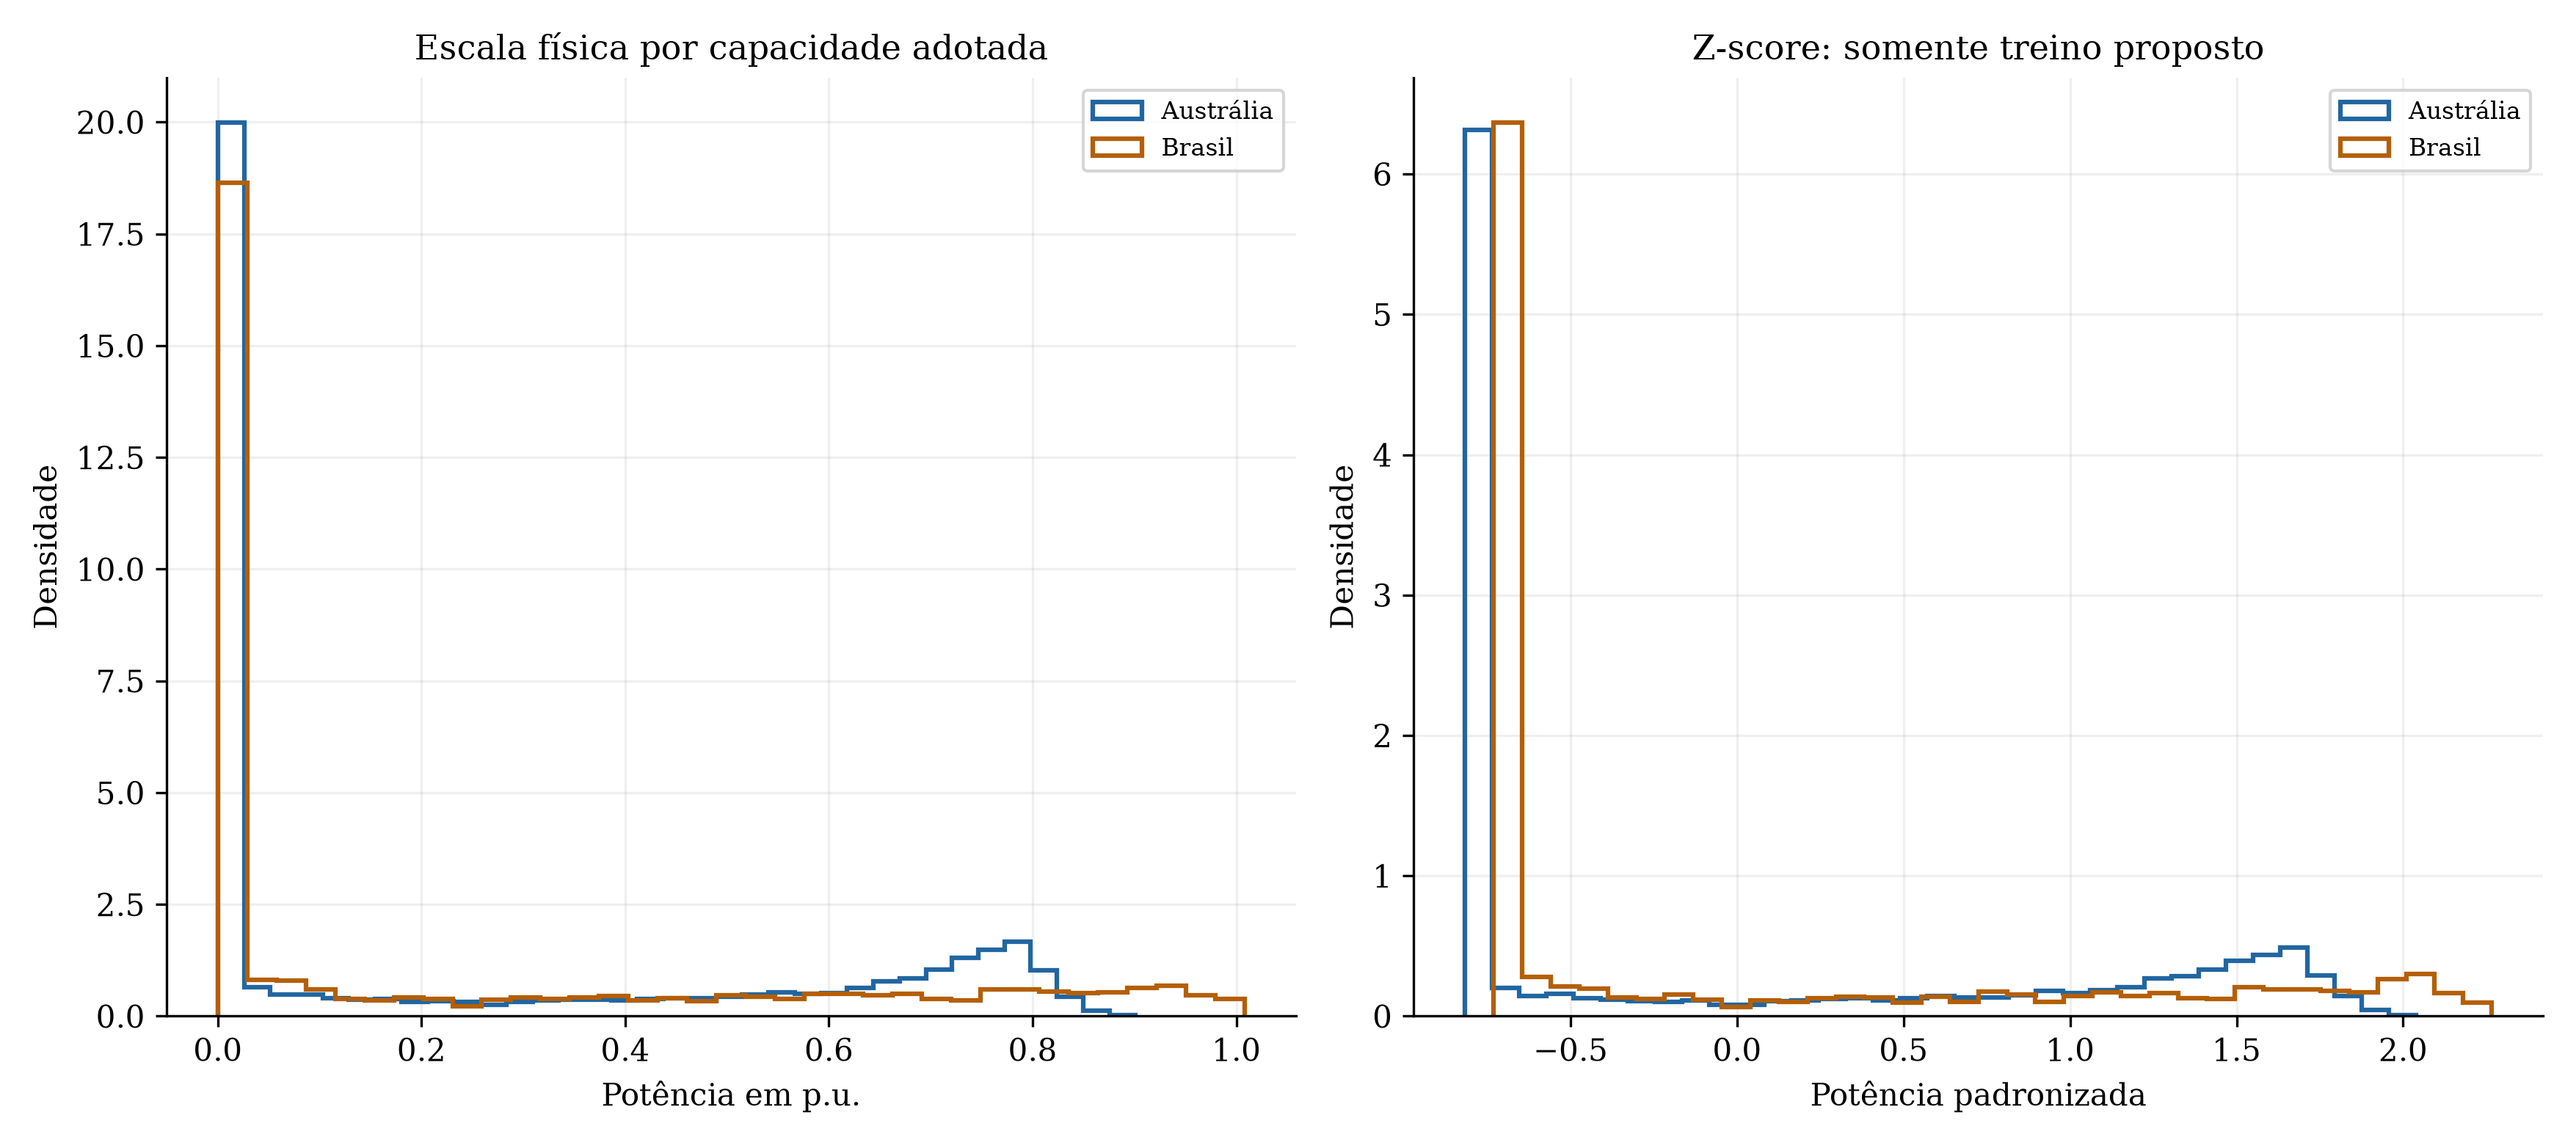

**Figura 3.3-H08 — Normalização de potência e preparação das novas escalas.** Distingue-se AP/máximo do período, usada apenas para replicar a triagem retrospectiva dos autores, de AP/capacidade adotada (24/1000 kW) e do z-score ajustado nos primeiros 70% das horas elegíveis de todos os blocos. As partições 70/15/15 são propostas preparatórias; nenhum modelo ou resultado antigo foi recalculado.

In [20]:
fig,ax=plt.subplots(1,2,figsize=(11.7,5.2))
for dom,nome,cor in [('australia','Austrália',azul),('brasil','Brasil',laranja)]:
    s=processamento['frames'][dom];ax[0].hist(s.potencia_pu_capacidade,bins=35,density=True,histtype='step',lw=1.5,label=nome,color=cor)
    ax[1].hist(s.loc[s.particao_proposta.eq('treino'),'potencia_z_treino'],bins=35,density=True,histtype='step',lw=1.5,label=nome,color=cor)
ax[0].set(title='Escala física por capacidade adotada',xlabel='Potência em p.u.',ylabel='Densidade')
ax[1].set(title='Z-score: somente treino proposto',xlabel='Potência padronizada',ylabel='Densidade')
for a in ax:a.legend();a.grid(alpha=.2)
salvar(fig,'fig_3_3_h08_escalas','Normalização de potência e preparação das novas escalas',
       'Distingue-se AP/máximo do período, usada apenas para replicar a triagem retrospectiva dos autores, de AP/capacidade adotada (24/1000 kW) e do z-score ajustado nos primeiros 70% das horas elegíveis de todos os blocos. As partições 70/15/15 são propostas preparatórias; nenhum modelo ou resultado antigo foi recalculado.')

figura(8)

In [21]:
(processamento['pasta']/'indice_figuras.json').write_text(json.dumps(indice,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
texto='# Figuras 3.3 — tratamento horário baseado em Bak et al.\n\nPNG: 300 dpi; PDF vetorial. Numeração provisória.\n\n'
for i in indice:texto+=f"## {i['arquivo']}\n\n{i['titulo']}\n\n{i['legenda']}\n\nFonte: elaboração própria; método e adaptações registrados no manifesto.\n\n"
(processamento['pasta']/'legendas_figuras.md').write_text(texto,encoding='utf-8');processamento['indice_figuras']=indice

### Arquivos preparados e pontos de interpretação

Os CSVs de entrada não são alterados. As novas bases estão em `data/processed/australia/` e `data/processed/brasil/`, com nomes contendo `horario_bak2025` ou `bak2025_diario_derivado`. As bases completas de calendário preservam os dias descartados como lacunas; os arquivos `*_todos_blocos.csv.gz` são as bases principais com datas originais e `bloco_id`; `*_bloco.csv.gz` conserva o maior intervalo somente para diagnóstico.

O relatório `reports/tcc/preprocessamento_horario_bak2025/` reúne figuras PNG/PDF, tabelas, legendas e manifesto com hashes das fontes e identificadores dos dois arquivos de referência dos autores.

O texto do TCC deve descrever este procedimento como **baseado na implementação de Bak et al., com adaptações explícitas**. A hora com média disponível pode conter coleta parcial; a unidade original do vento australiano requer confirmação; a soma brasileira pode ser parcial; e o limite por máximo do período pertence à análise retrospectiva.

Não se devem atribuir a essas novas bases as métricas dos experimentos anteriores. Uma nova comparação preditiva exigirá reconstruir as janelas e avaliar apenas alvos adequados, respeitando a disponibilidade temporal das estimativas.

A Austrália também possui `australia_horario_bak2025_auditoria_canais.csv.gz`, com os onze canais numéricos, exceto direção do vento, suas contagens e os valores após QC. Esse arquivo de auditoria pode conter ausências e não substitui a base com as cinco entradas completas. Arquivos antigos de controle ou decisões univariadas que permaneçam na pasta não fazem parte desta configuração; o manifesto e a tabela `decisao_final_todos_blocos.csv` identificam as saídas vigentes.

In [22]:
exportados = pd.DataFrame.from_dict(processamento["meta"]["exportados"], orient="index")
display(exportados[["arquivo", "linhas"]])
print("Tabelas:", processamento["tabelas_dir"])
print("Figuras:", processamento["figuras"])
print("Manifesto:", PASTA / "manifesto.json")
print("Legendas:", PASTA / "legendas_figuras.md")
print("Fontes preservadas; modelos anteriores não foram modificados.")

Tabelas: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\preprocessamento_horario_bak2025\tabelas
Figuras: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\preprocessamento_horario_bak2025\figuras
Manifesto: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\preprocessamento_horario_bak2025\manifesto.json
Legendas: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\preprocessamento_horario_bak2025\legendas_figuras.md
Fontes preservadas; modelos anteriores não foram modificados.


,arquivo,linhas
australia_todos_blocos,data/processed/australia/australia_horario_bak2025_todos_blocos.csv.gz,26710
australia_maior_bloco,data/processed/australia/australia_horario_bak2025_bloco.csv.gz,6192
australia_diario_derivado,data/processed/australia/australia_bak2025_diario_derivado.csv.gz,1111
australia_calendario,data/processed/australia/australia_horario_bak2025_calendario.csv.gz,105864
brasil_todos_blocos,data/processed/brasil/brasil_horario_bak2025_todos_blocos.csv.gz,6310
brasil_maior_bloco,data/processed/brasil/brasil_horario_bak2025_bloco.csv.gz,792
brasil_diario_derivado,data/processed/brasil/brasil_bak2025_diario_derivado.csv.gz,261
brasil_calendario,data/processed/brasil/brasil_horario_bak2025_calendario.csv.gz,8736
australia_auditoria_canais,data/processed/australia/australia_horario_bak2025_auditoria_canais.csv.gz,105864


## Estudo complementar — covariáveis da estação brasileira na resolução horária

**Objetivo:** registrar a avaliação de GHI, temperatura do ar e umidade relativa que fundamenta a decisão de manter somente potência **no Brasil** e incluir todos os seus blocos. Os cenários multivariados abaixo são diagnósticos e **não são a configuração escolhida**. **Vento excluído deste diagnóstico da estação brasileira e das entradas brasileiras**, conforme solicitado. Os blocos principais preparados acima continuam sendo a referência de comparação; este diagnóstico não substitui as bases nem treina modelos.

Correspondência semântica não comprova equivalência de unidade, calibração ou disponibilidade. Para GHI, usamos a **irradiância global horizontal média**: média horária em unidade nominal de W/m², ainda não confirmada no Brasil. Não usamos os contadores `ghi_kwh_*` como se fossem irradiância, nem POA (plano inclinado) como GHI. A palavra “Irradiation” na figura não altera essa definição.

O teste usa a mesma grade local do processamento de potência, do primeiro ao último dia com registro elétrico. Compara a disponibilidade em todo esse calendário e dentro das 792 horas do maior bloco brasileiro, mantido apenas como comparação. Temperatura e GHI também são confrontados com os canais alternativos da própria estação, sem misturá-los automaticamente: são estatísticas do mesmo instrumento, não novas observações independentes.

In [23]:
ESTUDO = PASTA / "estudo_estacao_sem_vento"
ESTUDO.mkdir(exist_ok=True)
correspondencias = pd.DataFrame([
    ("AP", "Active_Power", "total_active_power_w / 1000", "kW", "Potência da soma disponível; verificar oito contribuintes"),
    ("GHI", "Global_Horizontal_Radiation", "ghi_irr_med", "W/m² nominal, a confirmar", "Alternativa: ghi_irradiancia; escala brasileira pendente"),
    ("Temp", "Weather_Temperature_Celsius", "air_temperature_med", "°C nominal", "Alternativa: temperatura_ambiente; não usar temperatura do painel"),
    ("RH", "Weather_Relative_Humidity", "Não existe coluna no consolidado", "%", "Não pode ser reconstruída por interpolação sem observações"),
], columns=["variavel", "australia", "brasil", "unidade", "observacao"])

def numerica_estacao(coluna):
    return pd.to_numeric(br[coluna], errors="coerce").replace([np.inf, -np.inf], np.nan)

origem_estudo = pd.DataFrame({
    "AP": numerica_estacao("total_active_power_w") / 1000,
    "Temp": numerica_estacao("air_temperature_med"),
    "GHI": numerica_estacao("ghi_irr_med"),
    # Ausência estrutural explícita; não é uma leitura medida.
    "RH": np.nan,
}, index=br.index)
horas_estudo, contagens_estudo = agregar_horas(origem_estudo)
horas_estudo = horas_estudo.reindex(horario_br.index)
contagens_estudo = contagens_estudo.reindex(horario_br.index)
bloco_atual = processamento["frames_maiores"]["brasil"]

cobertura_estacao = []
for coluna in horas_estudo:
    s = horas_estudo[coluna]
    sb = s.reindex(bloco_atual.index)
    lacunas = blocos_consecutivos(s.isna())
    maior_lacuna = lacunas.loc[lacunas.horas.idxmax()] if len(lacunas) else None
    cobertura_estacao.append(dict(
        variavel=coluna, horas_calendario=len(s), horas_com_dado=int(s.notna().sum()),
        faltantes_pct=float(s.isna().mean()*100),
        horas_bloco_atual=len(sb), presentes_bloco_atual=int(sb.notna().sum()),
        faltantes_bloco_atual=int(sb.isna().sum()),
        maior_lacuna_horas=int(maior_lacuna.horas) if maior_lacuna is not None else 0,
        inicio_maior_lacuna=maior_lacuna.inicio if maior_lacuna is not None else pd.NaT,
        fim_maior_lacuna=maior_lacuna.fim if maior_lacuna is not None else pd.NaT))
cobertura_estacao = pd.DataFrame(cobertura_estacao)
# A potência aqui é a média original: três horas do bloco principal foram interpoladas.
display(correspondencias)
display(cobertura_estacao)

,variavel,australia,brasil,unidade,observacao
0,AP,Active_Power,total_active_power_w / 1000,kW,Potência da soma disponível; verificar oito contribuintes
1,GHI,Global_Horizontal_Radiation,ghi_irr_med,"W/m² nominal, a confirmar",Alternativa: ghi_irradiancia; escala brasileira pendente
2,Temp,Weather_Temperature_Celsius,air_temperature_med,°C nominal,Alternativa: temperatura_ambiente; não usar temperatura do painel
3,RH,Weather_Relative_Humidity,Não existe coluna no consolidado,%,Não pode ser reconstruída por interpolação sem observações


,variavel,horas_calendario,horas_com_dado,faltantes_pct,horas_bloco_atual,presentes_bloco_atual,faltantes_bloco_atual,maior_lacuna_horas,inicio_maior_lacuna,fim_maior_lacuna
0,AP,8736,7542,13.6676,792,789,3,129,2025-01-08 00:00:00,2025-01-13 08:00:00
1,Temp,8736,2870,67.1474,792,535,257,5017,2025-01-31 13:00:00,2025-08-28 13:00:00
2,GHI,8736,2870,67.1474,792,535,257,5017,2025-01-31 13:00:00,2025-08-28 13:00:00
3,RH,8736,0,100.0000,792,0,792,8736,2025-01-02 00:00:00,2025-12-31 23:00:00


### Triagem e efeito das lacunas na seleção

Aplicam-se as regras elétricas já adotadas, temperatura abaixo de −10 °C e GHI acima de 2000 na escala informada. **As regras cruzadas AP × GHI ficam desativadas neste diagnóstico principal**, porque dependem de confirmar a unidade/escala do GHI. Valores negativos de GHI são contados e mostrados, sem correção automática: o código dos autores não os invalida por essa regra isolada.

Para cada conjunto de entradas, o teste recomeça nas médias horárias originais: reprova dias com duas faltas consecutivas em qualquer coluna exigida e interpola somente uma hora isolada com duas bordas válidas. Não usa as horas já interpoladas do cenário univariado como se fossem medições. A umidade inteiramente ausente impede qualquer linha completa do conjunto AP + Temp + GHI + RH.

O número total de horas aproveitáveis pode abranger **vários blocos separados**. Ele não é a duração de uma única série contínua e não autoriza janelas que atravessem as interrupções.

In [24]:
qc_estudo = horas_estudo.copy()
qc_ap, _, _, _ = limpar_anomalias(
    horas_estudo[["AP"]].rename(columns={"AP": "Active_Power"}), usar_meteorologia=False)
qc_estudo["AP"] = qc_ap["Active_Power"]
qc_estudo.loc[qc_estudo.Temp.lt(-10), "Temp"] = np.nan
qc_estudo.loc[qc_estudo.GHI.gt(2000), "GHI"] = np.nan
qc_estudo.loc[(~qc_estudo.RH.between(0,100)) & qc_estudo.RH.notna(), "RH"] = np.nan

cenarios_estacao, tratados_estacao, imputados_estacao = [], {}, {}
for nome, colunas in [
    ("AP", ["AP"]), ("AP + Temp", ["AP", "Temp"]),
    ("AP + Temp + GHI", ["AP", "Temp", "GHI"]),
    ("AP + Temp + GHI + RH", ["AP", "Temp", "GHI", "RH"]),
]:
    final, im, disp, dias = remover_dias_e_interpolar(qc_estudo, colunas)
    completos = final[colunas].notna().all(axis=1)
    lista_cenario = blocos_consecutivos(completos)
    maior = lista_cenario.loc[lista_cenario.horas.idxmax()] if len(lista_cenario) else None
    tratados_estacao[nome] = final[colunas]
    imputados_estacao[nome] = im
    cenarios_estacao.append(dict(
        cenario=nome, horas_conjuntas_antes=int(horas_estudo[colunas].notna().all(axis=1).sum()),
        horas_aproveitaveis_total=int(completos.sum()), dias_civis_24h=int(dias.dia_24h_completo.sum()),
        quantidade_blocos=len(lista_cenario), maior_bloco_horas=int(maior.horas) if maior is not None else 0,
        maior_bloco_dias=float(maior.dias_equivalentes) if maior is not None else 0.,
        inicio=maior.inicio if maior is not None else pd.NaT,
        fim=maior.fim if maior is not None else pd.NaT,
        valores_interpolados=int(im.sum().sum())))
cenarios_estacao = pd.DataFrame(cenarios_estacao)
assert cenarios_estacao.iloc[0].maior_bloco_horas == len(bloco_atual)
assert cenarios_estacao.iloc[-1].horas_aproveitaveis_total == 0
assert not imputados_estacao["AP + Temp + GHI"].loc[
    qc_estudo.Temp.isna().rolling(2,min_periods=2).sum().ge(2), "Temp"].any()
display(cenarios_estacao)

# Diferença entre canais alternativos, sem fundir ou substituir registros.
alternativas = []
for principal, alternativa in [("air_temperature_med", "temperatura_ambiente"),
                              ("ghi_irr_med", "ghi_irradiancia")]:
    a, b = numerica_estacao(principal), numerica_estacao(alternativa)
    ok = a.notna() & b.notna()
    diferenca = (a[ok]-b[ok]).abs()
    alternativas.append(dict(principal=principal, alternativa=alternativa,
        pares_5min=int(ok.sum()), extras_exclusivos_alternativa=int((a.isna() & b.notna()).sum()),
        diferenca_absoluta_mediana=float(diferenca.median()),
        diferenca_absoluta_p95=float(diferenca.quantile(.95))))
alternativas = pd.DataFrame(alternativas)
display(alternativas)

,cenario,horas_conjuntas_antes,horas_aproveitaveis_total,dias_civis_24h,quantidade_blocos,maior_bloco_horas,maior_bloco_dias,inicio,fim,valores_interpolados
0,AP,7542,6310,261,30,792,33.0000,2025-08-18,2025-09-19 23:00:00,11
1,AP + Temp,2856,2544,106,7,696,29.0000,2025-10-19,2025-11-16 23:00:00,7
2,AP + Temp + GHI,2856,2544,106,7,696,29.0000,2025-10-19,2025-11-16 23:00:00,10
3,AP + Temp + GHI + RH,0,0,0,0,0,0.0000,NaT,NaT,0


,principal,alternativa,pares_5min,extras_exclusivos_alternativa,diferenca_absoluta_mediana,diferenca_absoluta_p95
0,air_temperature_med,temperatura_ambiente,33383,0,0.0783,0.3300
1,ghi_irr_med,ghi_irradiancia,33383,0,0.1995,7.5717


### Escala do GHI e cobertura australiana correspondente

Os perfis abaixo são diagnósticos de disponibilidade e consistência, não validações de calibração. A comparação de GHI entre janeiro (poucas horas) e agosto–dezembro usa amostras com cobertura muito diferente; uma diferença de escala aparente **não identifica, por si só, um fator de correção**. Não se multiplica o GHI por 10 nem se ajusta a escala usando a potência-alvo.

Na Austrália, temperatura e umidade existem no arquivo original, mas não foram exigidas nem exportadas como entradas nas horas selecionadas do cenário multivariado australiano. A auditoria abaixo verifica sua disponibilidade nesse intervalo, para evitar confundir existência da coluna com cobertura no recorte escolhido. O vento foi excluído deste estudo.

In [25]:
mensal_estacao = []
for mes, grupo in horas_estudo.groupby(horas_estudo.index.to_period("M")):
    mensal_estacao.append(dict(mes=str(mes), horas_calendario=len(grupo),
        horas_ap=int(grupo.AP.notna().sum()), horas_temp=int(grupo.Temp.notna().sum()),
        horas_ghi=int(grupo.GHI.notna().sum()), horas_rh=int(grupo.RH.notna().sum()),
        ghi_max_horario=float(grupo.GHI.max()), ghi_p99=float(grupo.GHI.quantile(.99)),
        horas_ghi_negativo=int(grupo.GHI.lt(0).sum())))
mensal_estacao = pd.DataFrame(mensal_estacao)
display(mensal_estacao)

au_aux = pd.read_csv(pa, usecols=["timestamp", "Weather_Temperature_Celsius", "Weather_Relative_Humidity"])
au_aux.index = pd.DatetimeIndex(pd.to_datetime(au_aux.pop("timestamp"), format="mixed"), name="timestamp")
au_aux_h, _ = agregar_horas(au_aux.sort_index())
au_recorte = processamento["frames"]["australia"]
au_cobertura_aux = pd.DataFrame([
    dict(variavel=coluna, horas_bloco=len(au_recorte),
         horas_presentes=int(au_aux_h[coluna].reindex(au_recorte.index).notna().sum()),
         horas_invalidas_pelo_limite=int((au_aux_h[coluna].lt(-10) if "Temperature" in coluna
             else (~au_aux_h[coluna].between(0,100)&au_aux_h[coluna].notna())).reindex(au_recorte.index).sum()))
    for coluna in au_aux_h])
display(au_cobertura_aux)

,mes,horas_calendario,horas_ap,horas_temp,horas_ghi,horas_rh,ghi_max_horario,ghi_p99,horas_ghi_negativo
0,2025-01,720,79,22,22,0,1100.1349,1086.0684,4
1,2025-02,672,652,0,0,0,NaN,NaN,0
2,2025-03,744,577,0,0,0,NaN,NaN,0
3,2025-04,720,707,0,0,0,NaN,NaN,0
4,2025-05,744,708,0,0,0,NaN,NaN,0
5,2025-06,720,649,0,0,0,NaN,NaN,0
6,2025-07,744,634,0,0,0,NaN,NaN,0
7,2025-08,744,727,82,82,0,83.7666,76.5906,28
8,2025-09,720,713,713,713,0,101.9460,75.3785,274
9,2025-10,744,729,729,729,0,83.2863,78.3364,254


,variavel,horas_bloco,horas_presentes,horas_invalidas_pelo_limite
0,Weather_Temperature_Celsius,26710,26709,0
1,Weather_Relative_Humidity,26710,26709,12


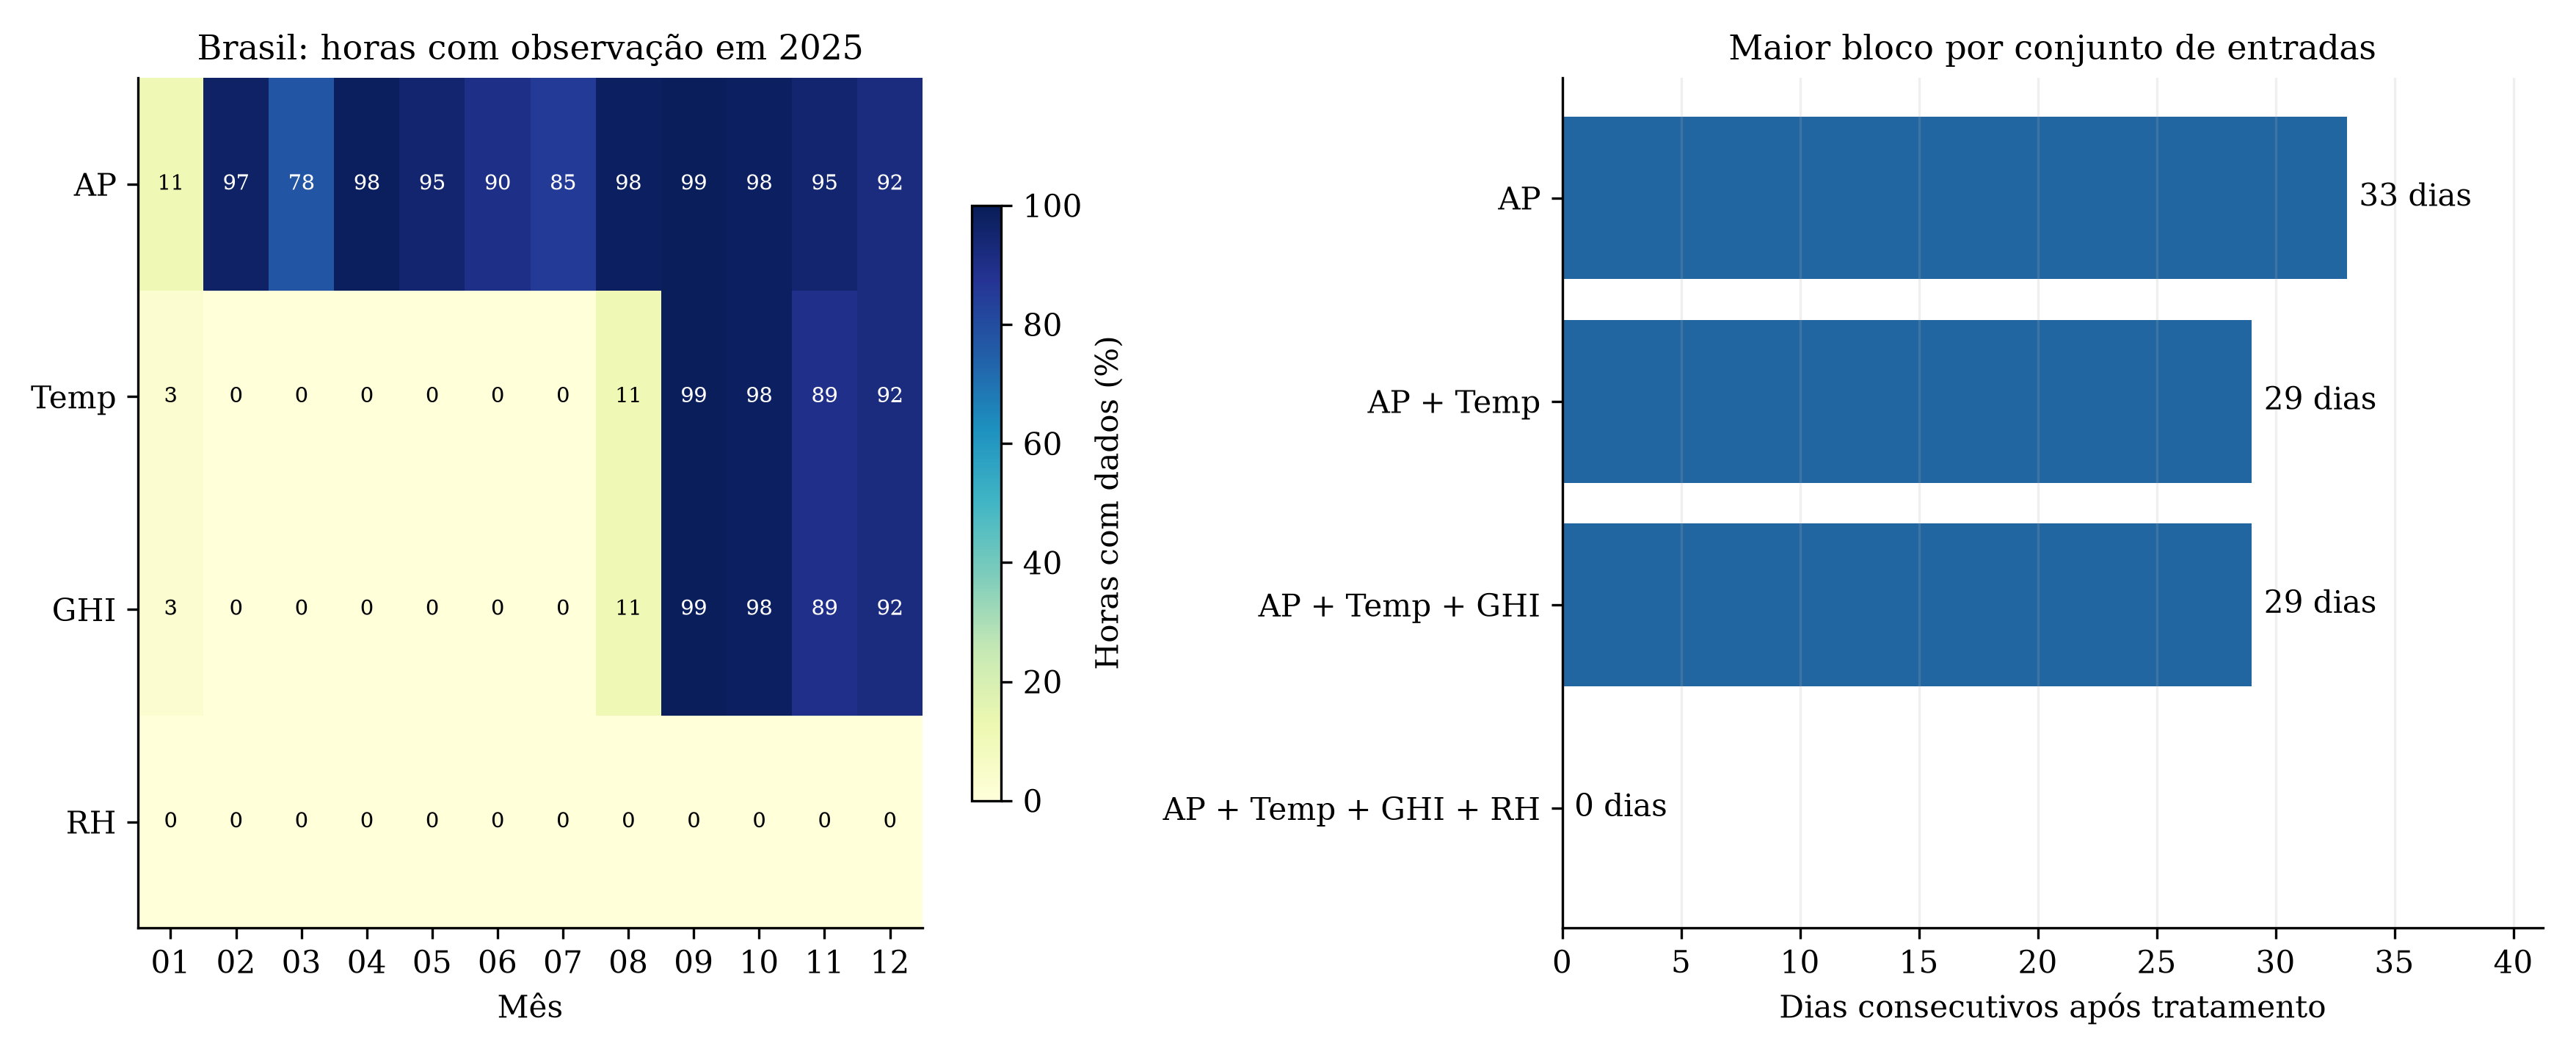

**Estação H01.** Disponibilidade das médias horárias originais por mês e maior bloco após o tratamento. O calendário começa no primeiro dia com potência; RH é ausência de variável. O cenário com GHI é candidato condicional à confirmação de sua escala. Fonte: elaboração própria.

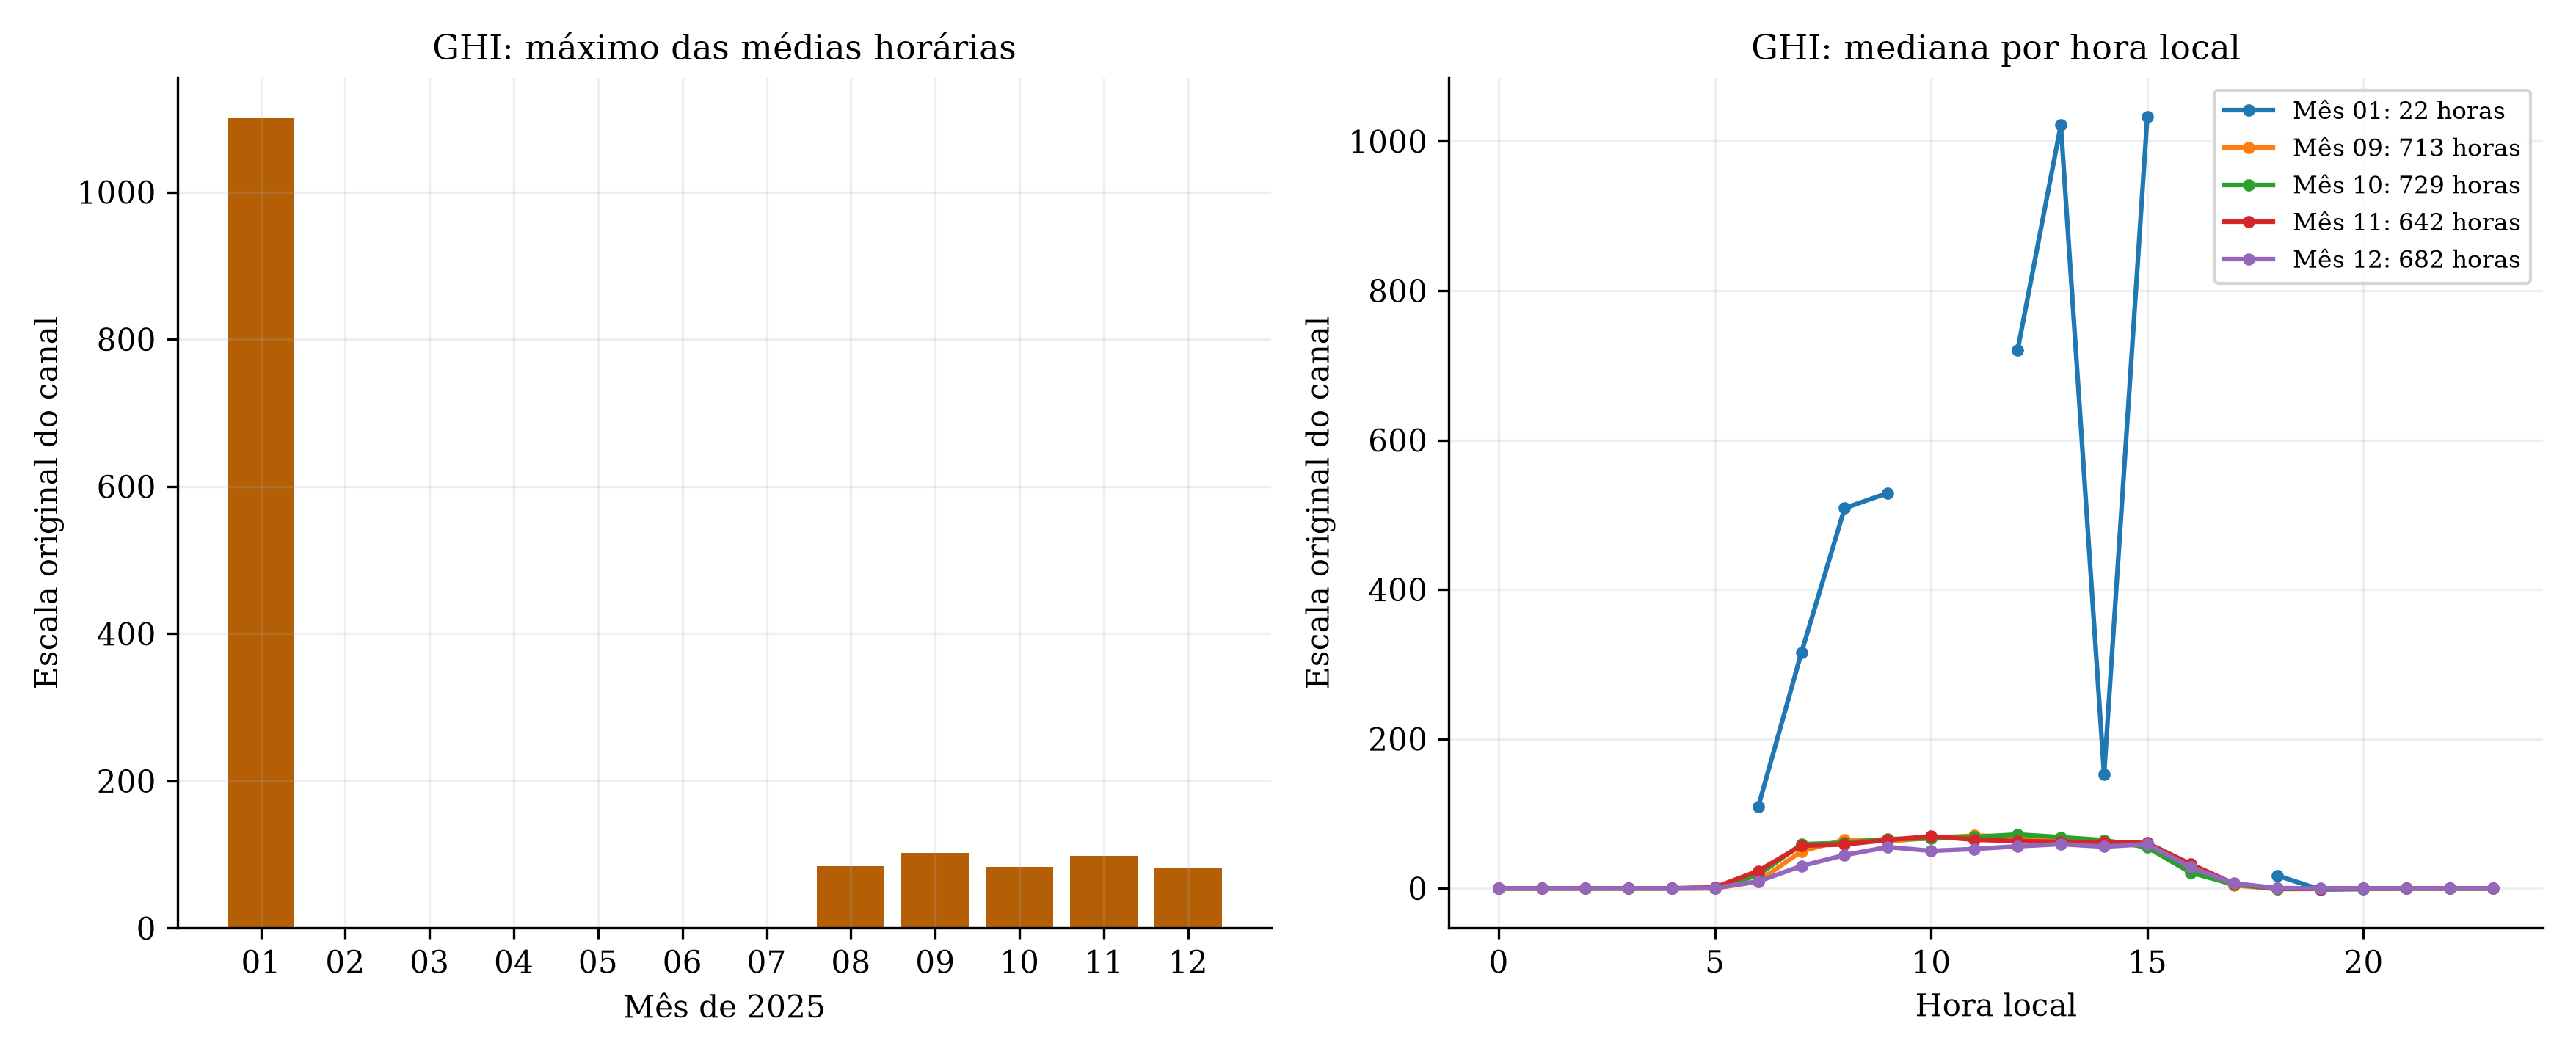

**Estação H02.** Máximos e perfis do GHI na escala informada. Janeiro possui somente 22 horas disponíveis, distribuídas em poucos dias; as amostras mensais não são diretamente comparáveis. A diferença motiva conferir configuração, unidade e calibração, sem presumir um fator de correção. Fonte: elaboração própria.

In [26]:
# Figura adicional 1: disponibilidade mensal e impacto das entradas exigidas.
fig, ax = plt.subplots(1, 2, figsize=(11.7, 4.8))
linhas = ["AP", "Temp", "GHI", "RH"]
meses = sorted(horas_estudo.index.to_period("M").unique())
matriz = np.array([[horas_estudo.loc[horas_estudo.index.to_period("M")==m, c].notna().mean()*100
                    for m in meses] for c in linhas])
imagem = ax[0].imshow(matriz, aspect="auto", vmin=0, vmax=100, cmap="YlGnBu")
ax[0].set_xticks(range(len(meses)), [str(m)[5:] for m in meses])
ax[0].set_yticks(range(len(linhas)), linhas)
ax[0].set(title="Brasil: horas com observação em 2025", xlabel="Mês")
for i in range(len(linhas)):
    for j in range(len(meses)):
        ax[0].text(j, i, f"{matriz[i,j]:.0f}", ha="center", va="center", fontsize=7,
                   color="white" if matriz[i,j]>65 else "black")
fig.colorbar(imagem, ax=ax[0], label="Horas com dados (%)", shrink=.7)
barras = ax[1].barh(cenarios_estacao.cenario, cenarios_estacao.maior_bloco_dias, color="#2166a1")
ax[1].bar_label(barras, labels=[f"{v:g} dias" for v in cenarios_estacao.maior_bloco_dias], padding=4)
ax[1].invert_yaxis(); ax[1].set(xlabel="Dias consecutivos após tratamento", title="Maior bloco por conjunto de entradas")
ax[1].margins(x=.25); ax[1].grid(axis="x", alpha=.2)
fig.tight_layout()
for extensao in ["png", "pdf"]:
    fig.savefig(ESTUDO / f"estacao_h01_cobertura_e_blocos.{extensao}", dpi=300, facecolor="white")
plt.close(fig)
display(Image(filename=str(ESTUDO/"estacao_h01_cobertura_e_blocos.png"), width=1100))
display(Markdown("**Estação H01.** Disponibilidade das médias horárias originais por mês e maior bloco após o tratamento. "
                 "O calendário começa no primeiro dia com potência; RH é ausência de variável. "
                 "O cenário com GHI é candidato condicional à confirmação de sua escala. Fonte: elaboração própria."))

# Figura adicional 2: perfil do GHI por mês, sem corrigir sua escala.
fig, ax = plt.subplots(1, 2, figsize=(11.7, 4.8))
para_mapa = mensal_estacao.set_index("mes").ghi_max_horario
barras = ax[0].bar(range(len(para_mapa)), para_mapa, color="#b45f06")
ax[0].set_xticks(range(len(para_mapa)), [str(m)[5:] for m in para_mapa.index])
ax[0].set(title="GHI: máximo das médias horárias", xlabel="Mês de 2025", ylabel="Escala original do canal")
for mes in [1, 9, 10, 11, 12]:
    s = horas_estudo.loc[horas_estudo.index.month==mes, "GHI"]
    perfil = s.groupby(s.index.hour).median()
    ax[1].plot(perfil.index, perfil, marker=".", label=f"Mês {mes:02d}: {s.notna().sum()} horas")
ax[1].set(title="GHI: mediana por hora local", xlabel="Hora local", ylabel="Escala original do canal")
ax[1].legend(fontsize=8)
for a in ax: a.grid(alpha=.2)
fig.tight_layout()
for extensao in ["png", "pdf"]:
    fig.savefig(ESTUDO / f"estacao_h02_diagnostico_ghi.{extensao}", dpi=300, facecolor="white")
plt.close(fig)
display(Image(filename=str(ESTUDO/"estacao_h02_diagnostico_ghi.png"), width=1100))
display(Markdown("**Estação H02.** Máximos e perfis do GHI na escala informada. Janeiro possui somente 22 horas disponíveis, "
                 "distribuídas em poucos dias; as amostras mensais não são diretamente comparáveis. "
                 "A diferença motiva conferir configuração, unidade e calibração, sem presumir um fator de correção. Fonte: elaboração própria."))

### Interpretação do diagnóstico e decisão final

- **Temperatura:** candidata mais direta para acrescentar à potência. A faixa e a variação diária são compatíveis com temperatura do ar, e as leituras principal/média são próximas. Isso não substitui conferir os metadados do sensor. O canal alternativo não acrescenta datas ausentes.
- **GHI:** existe e acompanha a cobertura da temperatura, mas a escala precisa ser confirmada antes de aplicar limiares físicos AP × GHI ou transferir um modelo que espere W/m². Temperatura + GHI dão o mesmo maior período que temperatura sozinha; incluir GHI não recupera meses sem estação. POA e contadores de energia não são substitutos diretos.
- **RH:** não há coluna de umidade relativa no consolidado. Interpolação linear ou KNN não recupera uma variável completamente não observada sem fonte/hipótese adicional. Não se deve tratar temperatura, chuva ou albedo como se fossem umidade medida.
- **Vento:** desconsiderado nas entradas candidatas, conforme solicitado.

**Decisão adotada:** Brasil com AP e todos os blocos elegíveis; Austrália com AP, GHI, temperatura, RH e vento. Os canais adicionais australianos ficam em auditoria. Temperatura, GHI, RH e vento continuam fora das entradas brasileiras. A temperatura brasileira tem dados potenciais, mas restringiria a cobertura; a escala do GHI e a ausência de RH impedem tratar as cinco entradas como equivalentes.

Os cenários com estação permanecem diagnósticos. Para uma transferência com o mesmo contrato de entradas, usa-se AP em ambos os domínios. Uma estratégia que utilize as covariáveis australianas precisará explicitar como adapta as entradas ao Brasil. Este notebook não escolhe essa arquitetura nem demonstra ganho preditivo.

A interpolação proposta trata poucas horas isoladas, não o período de aproximadamente 209 dias sem registros da estação. Não se recomenda preencher essa interrupção com uma reta ou KNN e apresentá-la como medição local. O estudo é uma verificação de viabilidade dos dados; não demonstra ganho preditivo nem define o tamanho suficiente de treino. Qualquer experimento subsequente deve preservar a distinção entre valores observados e estimados e a contribuição parcial dos inversores.

In [27]:
resumos_estacao = {
    "correspondencia_variaveis": correspondencias, "cobertura_horaria": cobertura_estacao,
    "cenarios_sem_vento": cenarios_estacao, "alternativas_estacao": alternativas,
    "cobertura_mensal": mensal_estacao, "australia_cobertura_auxiliar": au_cobertura_aux}
for nome, tabela in resumos_estacao.items():
    tabela.to_csv(ESTUDO / f"{nome}.csv", index=False)

melhor = cenarios_estacao.set_index("cenario").loc["AP + Temp + GHI"]
cob = cobertura_estacao.set_index("variavel")
resumo_texto = (
    "# Estudo rápido da estação brasileira horária — sem vento\n\n"
    "Referência de execução: notebook 03_03_tratamento_e_preprocessamento.ipynb, seção complementar.\n\n"
    f"Calendário elétrico: {len(horas_estudo):,} horas. Potência com média original: {int(cob.loc['AP','horas_com_dado']):,}. "
    f"Temperatura e GHI: {int(cob.loc['Temp','horas_com_dado']):,} horas cada; RH: zero, coluna inexistente.\n\n"
    f"No bloco atual de {len(bloco_atual)} horas, temperatura e GHI têm {int(cob.loc['Temp','presentes_bloco_atual'])} horas observadas "
    f"e {int(cob.loc['Temp','faltantes_bloco_atual'])} ausentes.\n\n"
    f"Após tratar AP + temperatura (+ GHI condicional à escala): {int(melhor.horas_aproveitaveis_total)} horas em blocos separados, "
    f"{int(melhor.dias_civis_24h)} dias civis completos. Maior bloco: {melhor.inicio} a {melhor.fim}, "
    f"{int(melhor.maior_bloco_horas)} horas ({melhor.maior_bloco_dias:g} dias).\n\n"
    "A maior lacuna da estação tem 5.017 horas: 31/01/2025 13h a 28/08/2025 13h, aproximadamente 209 dias. "
    "A interpolação de uma hora não a recupera. Os canais alternativos não acrescentam registros.\n\n"
    "Decisão final: Brasil com AP em todos os blocos; Austrália com AP, GHI, temperatura, RH e vento. Os cenários com estação são diagnósticos, não entradas escolhidas. GHI requer confirmar escala/calibração: máximo horário de janeiro próximo de 1100, "
    "contra aproximadamente 80–102 de agosto a dezembro; janeiro possui somente 22 horas de amostra. "
    "Não se infere fator de correção. Não há RH local. Temperatura, GHI, RH e vento estão excluídos das entradas brasileiras; AP é a entrada comum.\n\n"
    "A Austrália possui temperatura e RH na fonte original; a tabela auxiliar verifica o bloco selecionado. "
    "Os dados elétricos brasileiros podem conter somas parciais. Este estudo não altera as bases principais, "
    "não treina modelos e não demonstra ganho preditivo.\n")
(ESTUDO / "resumo.md").write_text(resumo_texto.replace("\n", "\n"), encoding="utf-8")
meta_estacao = dict(
    notebook=str(NOTEBOOK.relative_to(RAIZ)), vento_excluido=True,
    decisao_final="Brasil com AP em todos os blocos; Austrália com AP, GHI, temperatura, RH e vento; estudo da estação brasileira mantido",
    fonte_brasil=str(pb.relative_to(RAIZ)), fonte_brasil_sha256=sha256(pb),
    fonte_australia_sha256=sha256(pa),
    calendario_inicio=str(horas_estudo.index.min()), calendario_fim=str(horas_estudo.index.max()),
    regra="Médias horárias; QC individual; >=2 NaN seguidos reprovam dia; interpolação só de uma hora interna",
    regra_cruzada_ghi_ap_aplicada=False,
    motivo="Escala do GHI brasileiro não confirmada; dados permanecem em sua escala original",
    exportados={str(f.name): sha256(f) for f in sorted(ESTUDO.iterdir()) if f.is_file() and f.name!="manifesto.json"})
(ESTUDO / "manifesto.json").write_text(json.dumps(meta_estacao, ensure_ascii=False, indent=2)+"\n", encoding="utf-8")
display(Markdown(resumo_texto.replace("\n", "\n")))
print("Diagnóstico exportado em:", ESTUDO)

Diagnóstico exportado em: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\preprocessamento_horario_bak2025\estudo_estacao_sem_vento


# Estudo rápido da estação brasileira horária — sem vento

Referência de execução: notebook 03_03_tratamento_e_preprocessamento.ipynb, seção complementar.

Calendário elétrico: 8,736 horas. Potência com média original: 7,542. Temperatura e GHI: 2,870 horas cada; RH: zero, coluna inexistente.

No bloco atual de 792 horas, temperatura e GHI têm 535 horas observadas e 257 ausentes.

Após tratar AP + temperatura (+ GHI condicional à escala): 2544 horas em blocos separados, 106 dias civis completos. Maior bloco: 2025-10-19 00:00:00 a 2025-11-16 23:00:00, 696 horas (29 dias).

A maior lacuna da estação tem 5.017 horas: 31/01/2025 13h a 28/08/2025 13h, aproximadamente 209 dias. A interpolação de uma hora não a recupera. Os canais alternativos não acrescentam registros.

Decisão final: Brasil com AP em todos os blocos; Austrália com AP, GHI, temperatura, RH e vento. Os cenários com estação são diagnósticos, não entradas escolhidas. GHI requer confirmar escala/calibração: máximo horário de janeiro próximo de 1100, contra aproximadamente 80–102 de agosto a dezembro; janeiro possui somente 22 horas de amostra. Não se infere fator de correção. Não há RH local. Temperatura, GHI, RH e vento estão excluídos das entradas brasileiras; AP é a entrada comum.

A Austrália possui temperatura e RH na fonte original; a tabela auxiliar verifica o bloco selecionado. Os dados elétricos brasileiros podem conter somas parciais. Este estudo não altera as bases principais, não treina modelos e não demonstra ganho preditivo.


## Configuração final adotada — todos os blocos e variáveis australianas

**Brasil:** todas as horas elegíveis de potência ativa, mantendo as datas originais, `bloco_id`, máscaras e contagens de contribuição dos inversores. Os dias com 24 valores horários originam a base diária auxiliar. O maior bloco de 33 dias é apenas uma parte desse total; os demais períodos não são descartados por serem menores.

**Austrália:** todos os blocos simultaneamente completos para AP, GHI, temperatura do ar, RH e vento. Outros canais elétricos, de irradiância e chuva são preservados no arquivo horário de auditoria. Vento está incluído na Austrália conforme a imagem; permanece fora das entradas brasileiras. Contadores acumulados não são tratados como potência.

**Continuidade:** os CSVs compactos não formam uma única sequência temporal. `bloco_id` impede atravessar as interrupções. As partições propostas seguem a ordem cronológica de todas as horas elegíveis. A auditoria de janelas usa 24 horas de histórico e alvo uma hora à frente como exemplo, sem cruzar blocos ou partições nem acessar uma interpolação antes de sua disponibilidade. Há contagens separadas de alvos observados para avaliação.

**Transferência:** a entrada física comum é AP. Um modelo australiano com cinco entradas terá contrato diferente do brasileiro; os dados preparados não autorizam carregar diretamente camadas incompatíveis. Essa escolha de arquitetura ficará para o experimento de treino. Nenhum modelo foi retreinado aqui.

As tabelas abaixo separam total aproveitável, dias completos, quantidade de blocos e maior sequência. As máscaras, bloco, partição, contagens e versões normalizadas são metadados ou representações alternativas, não novas medições.

In [28]:
decisao_final = tabelas["resumo_todos_blocos"].copy()
for dominio, dados in processamento["frames"].items():
    cols = COLUNAS_POR_DOMINIO[dominio]
    assert dados[cols].notna().all().all()
    assert dados.index.is_unique and dados.index.is_monotonic_increasing
    for _, grupo in dados.groupby("bloco_id", sort=False):
        validar_horas(grupo.index)
    assert dados.bloco_id.nunique() == int(decisao_final.set_index("dominio").loc[dominio,"blocos"])
print("Brasil: todas as horas elegíveis de potência, com identificador de bloco.")
print("Austrália: entradas candidatas", COLUNAS_AU)
print("Entrada física comum disponível para transferência direta:", COLUNAS_COMUNS)
display(decisao_final)
decisao_final.to_csv(PASTA / "tabelas/decisao_final_todos_blocos.csv", index=False)
resumo_janelas = []
for dominio, tabela in processamento["janelas"].items():
    for particao, grupo in tabela.groupby("particao", sort=False):
        resumo_janelas.append(dict(dominio=dominio, particao=particao,
            janelas=len(grupo), alvos_observados=int(grupo.alvo_observado.sum())))
resumo_janelas = pd.DataFrame(resumo_janelas)
display(resumo_janelas)
resumo_janelas.to_csv(PASTA / "tabelas/resumo_janelas_blocos.csv", index=False)
contrato_entradas = pd.DataFrame([
    ("GHI", "Global_Horizontal_Radiation", "W/m² nominal", "Fora das entradas BR; escala local pendente"),
    ("Temperatura do ar", "Weather_Temperature_Celsius", "°C", "Fora das entradas BR por decisão de cobertura"),
    ("Umidade relativa", "Weather_Relative_Humidity", "%", "Sem coluna medida no consolidado BR"),
    ("Velocidade do vento", "Wind_Speed", "Unidade original a confirmar", "Fora das entradas BR conforme decisão anterior"),
    ("Potência ativa", "Active_Power", "kW", "Entrada BR: total_active_power_w / 1000"),
], columns=["variavel_imagem", "coluna_australia", "unidade_au", "situacao_brasil"])
assert set(contrato_entradas.coluna_australia) == set(COLUNAS_AU)
display(contrato_entradas)
contrato_entradas.to_csv(PASTA / "tabelas/contrato_entradas_por_dominio.csv", index=False)

Brasil: todas as horas elegíveis de potência, com identificador de bloco.
Austrália: entradas candidatas ['Active_Power', 'Global_Horizontal_Radiation', 'Weather_Temperature_Celsius', 'Weather_Relative_Humidity', 'Wind_Speed']
Entrada física comum disponível para transferência direta: ['Active_Power']


,dominio,inicio,fim,horas_aproveitaveis,dias_completos,blocos,maior_bloco_horas,maior_bloco_dias,colunas_exigidas
0,australia,2013-07-26,2016-10-20 23:00:00,26710,1111,28,6192,258.0000,Active_Power; Global_Horizontal_Radiation; Weather_Temperature_Celsius; Weather_Relative_Humidit...
1,brasil,2025-01-30,2025-12-30 23:00:00,6310,261,30,792,33.0000,Active_Power


,dominio,particao,janelas,alvos_observados
0,australia,treino,18477,17540
1,australia,validacao,3836,3781
2,australia,teste,3662,3566
3,brasil,treino,3809,3801
4,brasil,validacao,897,896
5,brasil,teste,825,823


,variavel_imagem,coluna_australia,unidade_au,situacao_brasil
0,GHI,Global_Horizontal_Radiation,W/m² nominal,Fora das entradas BR; escala local pendente
1,Temperatura do ar,Weather_Temperature_Celsius,°C,Fora das entradas BR por decisão de cobertura
2,Umidade relativa,Weather_Relative_Humidity,%,Sem coluna medida no consolidado BR
3,Velocidade do vento,Wind_Speed,Unidade original a confirmar,Fora das entradas BR conforme decisão anterior
4,Potência ativa,Active_Power,kW,Entrada BR: total_active_power_w / 1000
